# Case Study: Diagnosing Breast Tumors with Gaussian Naive Bayes

**Dataset:** Breast Cancer Wisconsin (Diagnostic), `sklearn.datasets.load_breast_cancer`  
**Model:** `sklearn.naive_bayes.GaussianNB`  
**Question:** Can we predict whether a tumor is **malignant** or **benign** from continuous measurements of cell nuclei (radius, texture, smoothness, ...) taken from a digitized image of a fine-needle aspirate (FNA)?

This notebook is written as a *decision-making* case study rather than a "fit a model and print accuracy" tutorial. The central question is:

> **How do we decide, with evidence, whether Naive Bayes is a good choice for this problem?**

We answer it by turning the assumptions of Gaussian Naive Bayes into testable questions, checking each one against the data with visualizations, and then confirming (or refuting) our reasoning with properly validated experiments.

### Roadmap

| Part | What we do | Assumption / question it addresses |
|---|---|---|
| 1 | Load and understand the data | What are we modeling? |
| 2 | Naive Bayes in one page | What does the model actually assume? |
| 3 | The decision framework | Which questions must the data answer? |
| 4 | Feature types | Which Naive Bayes *variant* fits? |
| 5 | Distribution shapes and normality | Is the *Gaussian* likelihood reasonable? |
| 6 | How distributions affect modeling choices | Skew, zeros, unequal variances, transforms |
| 7 | Conditional independence | Is the *naive* assumption reasonable? |
| 8 | Class separability | Does each feature carry signal? |
| 9 | Building and validating the model | Do our design choices actually help? |
| 10 | Probability calibration | Can we trust the probabilities? |
| 11 | Naive Bayes vs. other algorithms | Is NB competitive? |
| 12 | Clinical threshold and final test evaluation | What does it mean for patients? |
| 13 | Explaining individual predictions | Why did the model decide that? |
| 14 | Verdict | Is Naive Bayes a good choice? |

> ⚠️ **Disclaimer:** this is an educational exercise on a small, historical research dataset. It is not a diagnostic tool.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     cross_validate, cross_val_predict, learning_curve)
from sklearn.naive_bayes import GaussianNB, BernoulliNB, MultinomialNB
from sklearn.preprocessing import StandardScaler, PowerTransformer, MinMaxScaler
from sklearn.pipeline import make_pipeline
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (confusion_matrix, classification_report, roc_curve, roc_auc_score,
                             precision_recall_curve, average_precision_score, recall_score,
                             precision_score, accuracy_score, brier_score_loss, log_loss)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.precision", 4)

RANDOM_STATE = 42
PALETTE = {"malignant": "#d62728", "benign": "#1f77b4"}
CLASS_ORDER = ["benign", "malignant"]

---
## Part 1: Load and understand the data

Each of the 569 rows describes one tumor sample. Ten characteristics of the cell nuclei were measured on the image (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension), and for each one three summaries were recorded across all nuclei in the image:

- **mean**: the average value,
- **error**: the standard error,
- **worst**: the mean of the three largest values.

That gives 10 × 3 = **30 continuous features**.

**A labeling trap to avoid:** in scikit-learn's version, `target = 0` means **malignant** and `target = 1` means **benign**. In medicine the condition we are trying to detect is the *positive* class, so we create a new column `malignant` (1 = malignant, 0 = benign). Every recall, precision, and ROC curve in this notebook therefore refers to *detecting cancer*.

In [2]:
data = load_breast_cancer(as_frame=True)
df = data.frame.copy()

print("Original target names:", dict(enumerate(data.target_names)))

df["diagnosis"] = df["target"].map({0: "malignant", 1: "benign"})
df["malignant"] = (df["target"] == 0).astype(int)      # positive class = cancer
df = df.drop(columns="target")

feature_names = list(data.feature_names)
mean_feats  = [f for f in feature_names if f.startswith("mean ")]
error_feats = [f for f in feature_names if f.endswith(" error")]
worst_feats = [f for f in feature_names if f.startswith("worst ")]

print(f"Shape: {df.shape}  |  missing values: {df.isna().sum().sum()}")
df.head()

Original target names: {0: np.str_('malignant'), 1: np.str_('benign')}
Shape: (569, 32)  |  missing values: 0


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis,malignant
0,17.99,10.38,122.80,1001.0,0.1184,0.2776,0.3001,0.1471,0.2419,0.0787,...,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.1189,malignant,1
1,20.57,17.77,132.90,1326.0,0.0847,0.0786,0.0869,0.0702,0.1812,0.0567,...,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.0890,malignant,1
2,19.69,21.25,130.00,1203.0,0.1096,0.1599,0.1974,0.1279,0.2069,0.0600,...,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.0876,malignant,1
3,11.42,20.38,77.58,386.1,0.1425,0.2839,0.2414,0.1052,0.2597,0.0974,...,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.1730,malignant,1
4,20.29,14.34,135.10,1297.0,0.1003,0.1328,0.1980,0.1043,0.1809,0.0588,...,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.0768,malignant,1


In [3]:
# The 30 features are a 10 x 3 grid: base measurement x summary statistic
pd.DataFrame({"mean": mean_feats, "error (SE)": error_feats, "worst": worst_feats})

,mean,error (SE),worst
0,mean radius,radius error,worst radius
1,mean texture,texture error,worst texture
2,mean perimeter,perimeter error,worst perimeter
3,mean area,area error,worst area
4,mean smoothness,smoothness error,worst smoothness
5,mean compactness,compactness error,worst compactness
6,mean concavity,concavity error,worst concavity
7,mean concave points,concave points error,worst concave points
8,mean symmetry,symmetry error,worst symmetry
9,mean fractal dimension,fractal dimension error,worst fractal dimension


In [4]:
df[mean_feats].describe().T

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.1273,3.5240,6.9810,11.7000,13.3700,15.7800,28.1100
mean texture,569.0,19.2896,4.3010,9.7100,16.1700,18.8400,21.8000,39.2800
mean perimeter,569.0,91.9690,24.2990,43.7900,75.1700,86.2400,104.1000,188.5000
mean area,569.0,654.8891,351.9141,143.5000,420.3000,551.1000,782.7000,2501.0000
mean smoothness,569.0,0.0964,0.0141,0.0526,0.0864,0.0959,0.1053,0.1634
mean compactness,569.0,0.1043,0.0528,0.0194,0.0649,0.0926,0.1304,0.3454
mean concavity,569.0,0.0888,0.0797,0.0000,0.0296,0.0615,0.1307,0.4268
mean concave points,569.0,0.0489,0.0388,0.0000,0.0203,0.0335,0.0740,0.2012
mean symmetry,569.0,0.1812,0.0274,0.1060,0.1619,0.1792,0.1957,0.3040
mean fractal dimension,569.0,0.0628,0.0071,0.0500,0.0577,0.0615,0.0661,0.0974


Two things already stand out:

1. **Scales differ by orders of magnitude.** `mean area` is in the hundreds while `mean smoothness` is around 0.1. Naive Bayes estimates a separate mean and variance for every feature, so in principle scale should not matter. In Part 9 we will discover a subtle exception caused by `GaussianNB`'s `var_smoothing` parameter.
2. **Class balance.** Naive Bayes uses the class frequencies as **prior probabilities** $P(y)$, so the balance of the target is part of the model itself, not just a nuisance.

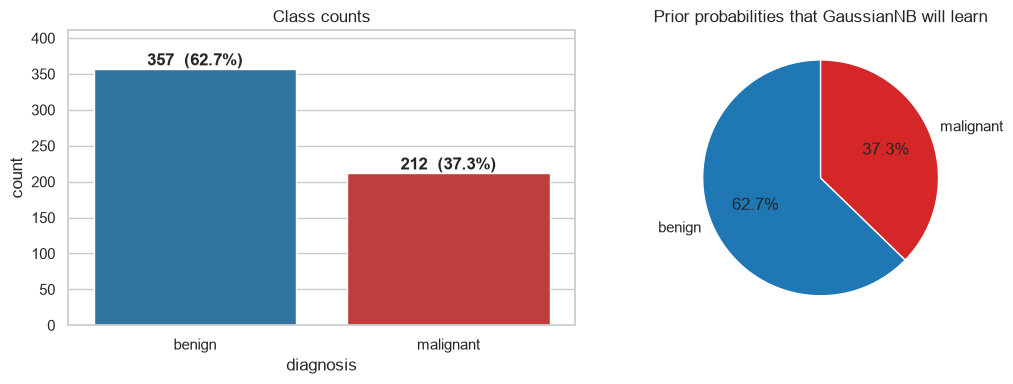

In [4]:
counts = df["diagnosis"].value_counts().reindex(CLASS_ORDER)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(data=df, x="diagnosis", order=CLASS_ORDER, hue="diagnosis",
              palette=PALETTE, legend=False, ax=axes[0])
for i, c in enumerate(counts):
    axes[0].text(i, c + 5, f"{c}  ({c / len(df):.1%})", ha="center", fontweight="bold")
axes[0].set_title("Class counts")
axes[0].set_ylim(0, counts.max() * 1.15)

axes[1].pie(counts, labels=counts.index, autopct="%1.1f%%", startangle=90,
            colors=[PALETTE[c] for c in counts.index], wedgeprops=dict(edgecolor="white"))
axes[1].set_title("Prior probabilities that GaussianNB will learn")
plt.tight_layout()
plt.show()

The classes are moderately imbalanced (~63% benign, ~37% malignant). This is not severe enough to require resampling, but two consequences follow:

- Plain **accuracy can be misleading**: a model that always says "benign" scores ~63%.
- The prior favors "benign", so for a patient whose measurements are ambiguous the model leans towards benign. Clinically, that is the *risky* direction. We will revisit this with threshold tuning in Part 12.

We will always use **stratified** splits so both classes keep these proportions.

## Part 2: Naive Bayes in one page

### Bayes' theorem
For a tumor with feature vector $\mathbf{x} = (x_1, \dots, x_{d})$:

$$
P(y \mid \mathbf{x}) \;=\; \frac{P(y)\; P(\mathbf{x} \mid y)}{P(\mathbf{x})} \;\propto\; P(y)\; P(\mathbf{x} \mid y)
$$

The hard part is $P(\mathbf{x} \mid y)$: a joint density over 30 dimensions. Estimating it directly would need far more than 569 samples.

### The "naive" assumption: conditional independence
Naive Bayes assumes the features are **independent given the class**:

$$
P(\mathbf{x} \mid y) \;=\; \prod_{i=1}^{d} P(x_i \mid y)
$$

One 30-dimensional problem becomes 30 one-dimensional problems. Note the condition *given the class*: features may be correlated overall (because both depend on the diagnosis) and the assumption can still hold. What matters is the correlation **within** each class. We test exactly that in Part 7.

### The "Gaussian" assumption: the shape of each 1-D likelihood
`GaussianNB` models each feature, within each class, as a normal distribution:

$$
P(x_i \mid y = c) \;=\; \frac{1}{\sqrt{2\pi\sigma_{ic}^2}}\exp\!\left(-\frac{(x_i - \mu_{ic})^2}{2\sigma_{ic}^2}\right)
$$

### The decision rule (computed in log space)

$$
\hat{y} = \arg\max_c \Big[\, \log P(y=c) + \sum_{i=1}^{d} \log P(x_i \mid y=c) \Big]
$$

For two classes, the **log posterior odds** is a simple sum of per-feature evidence:

$$
\log\frac{P(\text{malignant}\mid\mathbf{x})}{P(\text{benign}\mid\mathbf{x})}
= \underbrace{\log\frac{P(M)}{P(B)}}_{\text{prior}} + \sum_{i} \underbrace{\log\frac{P(x_i\mid M)}{P(x_i\mid B)}}_{\text{evidence from feature } i}
$$

This additive structure makes Naive Bayes unusually **interpretable** (Part 13).

### What the model learns
Just a mean and a variance per feature per class, plus the priors: $2 \times 30 \times 2 + 1 = 121$ numbers, all with closed-form estimates. Training requires no optimization and no learning rate, and it is very hard to overfit.

## Part 3: The decision framework

"Is Naive Bayes a good choice?" is too vague to answer directly. We break it into questions that the **data** can answer:

| # | Question | Why it matters for Naive Bayes | How we check it |
|---|---|---|---|
| Q1 | What *type* are the features? | Determines the variant: Gaussian, Multinomial, Bernoulli, Categorical | dtypes, unique counts, value ranges |
| Q2 | Is each feature roughly **normal within each class**? | `GaussianNB`'s likelihood is a normal curve; a bad shape gives bad likelihood ratios | Histograms + KDE, Q–Q plots, skewness |
| Q3 | Are features **conditionally independent**? | Violations cause *double counting* of evidence and overconfident probabilities | Within-class correlation heatmaps, pairplots |
| Q4 | Does each feature **separate the classes** on its own? | NB combines univariate evidence; it cannot discover interaction-only signal | Box/violin plots, effect sizes |
| Q5 | How much data do we have relative to features? | NB has few parameters (low variance), so it shines when $n$ is small | Learning curves |
| Q6 | Do we need **trustworthy probabilities** or **explanations**? | NB ranks well but is often miscalibrated; it is very interpretable | Calibration curves, evidence decomposition |
| Q7 | Does it hold up against **alternatives**? | A model is only "good" relative to what else we could use | Cross-validated comparison |

We will put a verdict on each row as we go and summarize them at the end.

## Part 4 (Q1): What type are the features? Choosing the Naive Bayes variant

scikit-learn ships several Naive Bayes variants. They differ **only** in the distribution they assume for $P(x_i \mid y)$:

| Variant | Assumed $P(x_i \mid y)$ | Natural data |
|---|---|---|
| `GaussianNB` | Normal $(\mu, \sigma^2)$ | Continuous real-valued measurements |
| `MultinomialNB` | Multinomial (counts) | Word counts, event frequencies |
| `ComplementNB` | Multinomial, complement-class estimates | Imbalanced text classification |
| `BernoulliNB` | Bernoulli (0/1) | Binary presence/absence features |
| `CategoricalNB` | Categorical | Discrete categories (color, blood type) |

So the first step is simply to look at what kind of values we have.

In [5]:
X_all = df[feature_names]
feature_types = pd.DataFrame({
    "dtype": X_all.dtypes.astype(str),
    "n_unique": X_all.nunique(),
    "pct_unique": (X_all.nunique() / len(X_all) * 100).round(1),
    "min": X_all.min(),
    "max": X_all.max(),
    "integer_valued": (X_all % 1 == 0).all(),
    "n_zeros": (X_all == 0).sum(),
})
feature_types

,dtype,n_unique,pct_unique,min,max,integer_valued,n_zeros
mean radius,float64,456,80.1,6.9810,28.1100,False,0
mean texture,float64,479,84.2,9.7100,39.2800,False,0
mean perimeter,float64,522,91.7,43.7900,188.5000,False,0
mean area,float64,539,94.7,143.5000,2501.0000,False,0
mean smoothness,float64,474,83.3,0.0526,0.1634,False,0
mean compactness,float64,537,94.4,0.0194,0.3454,False,0
mean concavity,float64,537,94.4,0.0000,0.4268,False,13
mean concave points,float64,542,95.3,0.0000,0.2012,False,13
mean symmetry,float64,432,75.9,0.1060,0.3040,False,0
mean fractal dimension,float64,499,87.7,0.0500,0.0974,False,0


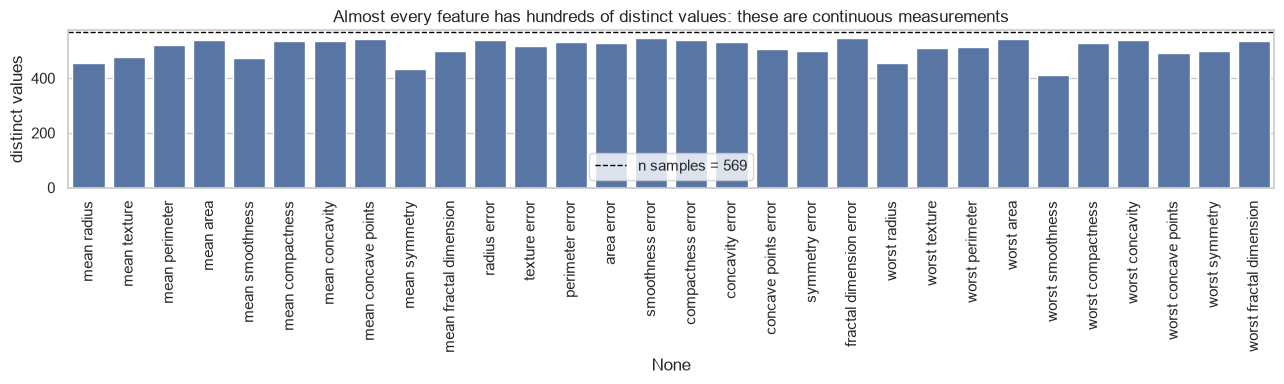

In [6]:
fig, ax = plt.subplots(figsize=(13, 4))
sns.barplot(x=feature_types.index, y=feature_types["n_unique"], color="#4c72b0", ax=ax)
ax.axhline(len(df), color="black", ls="--", lw=1, label=f"n samples = {len(df)}")
ax.set_ylabel("distinct values")
ax.set_title("Almost every feature has hundreds of distinct values: these are continuous measurements")
ax.tick_params(axis="x", rotation=90)
ax.legend()
plt.tight_layout()
plt.show()

**Q1 verdict: `GaussianNB` is the appropriate variant.**

- All 30 features are floating point, non-integer, and nearly every value is distinct. They are continuous physical measurements, not counts or categories.
- `MultinomialNB` would treat values as counts. A "count" of 0.0821 smoothness units is meaningless.
- `BernoulliNB` would need us to binarize, e.g. "radius above/below average", throwing away most of the information.

We do not need to take this on faith: in Part 9 we will run the mismatched variants anyway and measure the cost.

## Part 5 (Q2): Distribution shapes. Is a Gaussian likelihood reasonable?

`GaussianNB` replaces the true class-conditional distribution of every feature with a bell curve defined by two numbers. The question is not "is the data *exactly* normal" (real data never is) but **"is a bell curve a good enough summary to produce sensible likelihood ratios?"**

### 5.1 The three concept features: radius, texture, smoothness

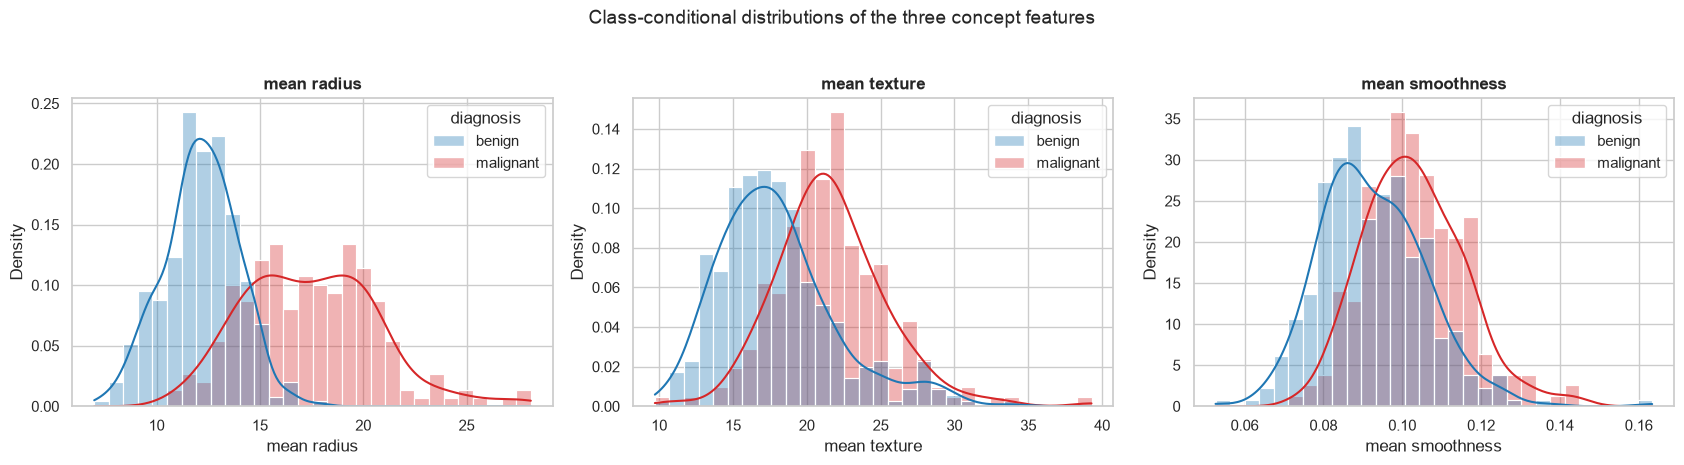

In [7]:
focus = ["mean radius", "mean texture", "mean smoothness"]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, feat in zip(axes, focus):
    sns.histplot(data=df, x=feat, hue="diagnosis", hue_order=CLASS_ORDER, palette=PALETTE,
                 stat="density", common_norm=False, kde=True, alpha=0.35, bins=30, ax=ax)
    ax.set_title(feat, fontweight="bold")
plt.suptitle("Class-conditional distributions of the three concept features", y=1.03, fontsize=14)
plt.tight_layout()
plt.show()

`common_norm=False` normalizes each class separately, so each curve is an estimate of $P(x_i \mid y)$, exactly the quantity Naive Bayes needs.

What we see:

- **mean radius**: two clearly separated humps; malignant tumors are larger *and* more variable (wider curve). Both look roughly bell-shaped with a mild right tail.
- **mean texture**: clear shift but heavy overlap; mostly bell-shaped with a slight right tail.
- **mean smoothness**: shifted only slightly; bell-shaped with a mild right tail.

### 5.2 What GaussianNB actually "sees"

Below, the dashed lines are the normal curves `GaussianNB` would fit (class mean and standard deviation). The gap between bars and dashed line is the **approximation error** of the Gaussian assumption.

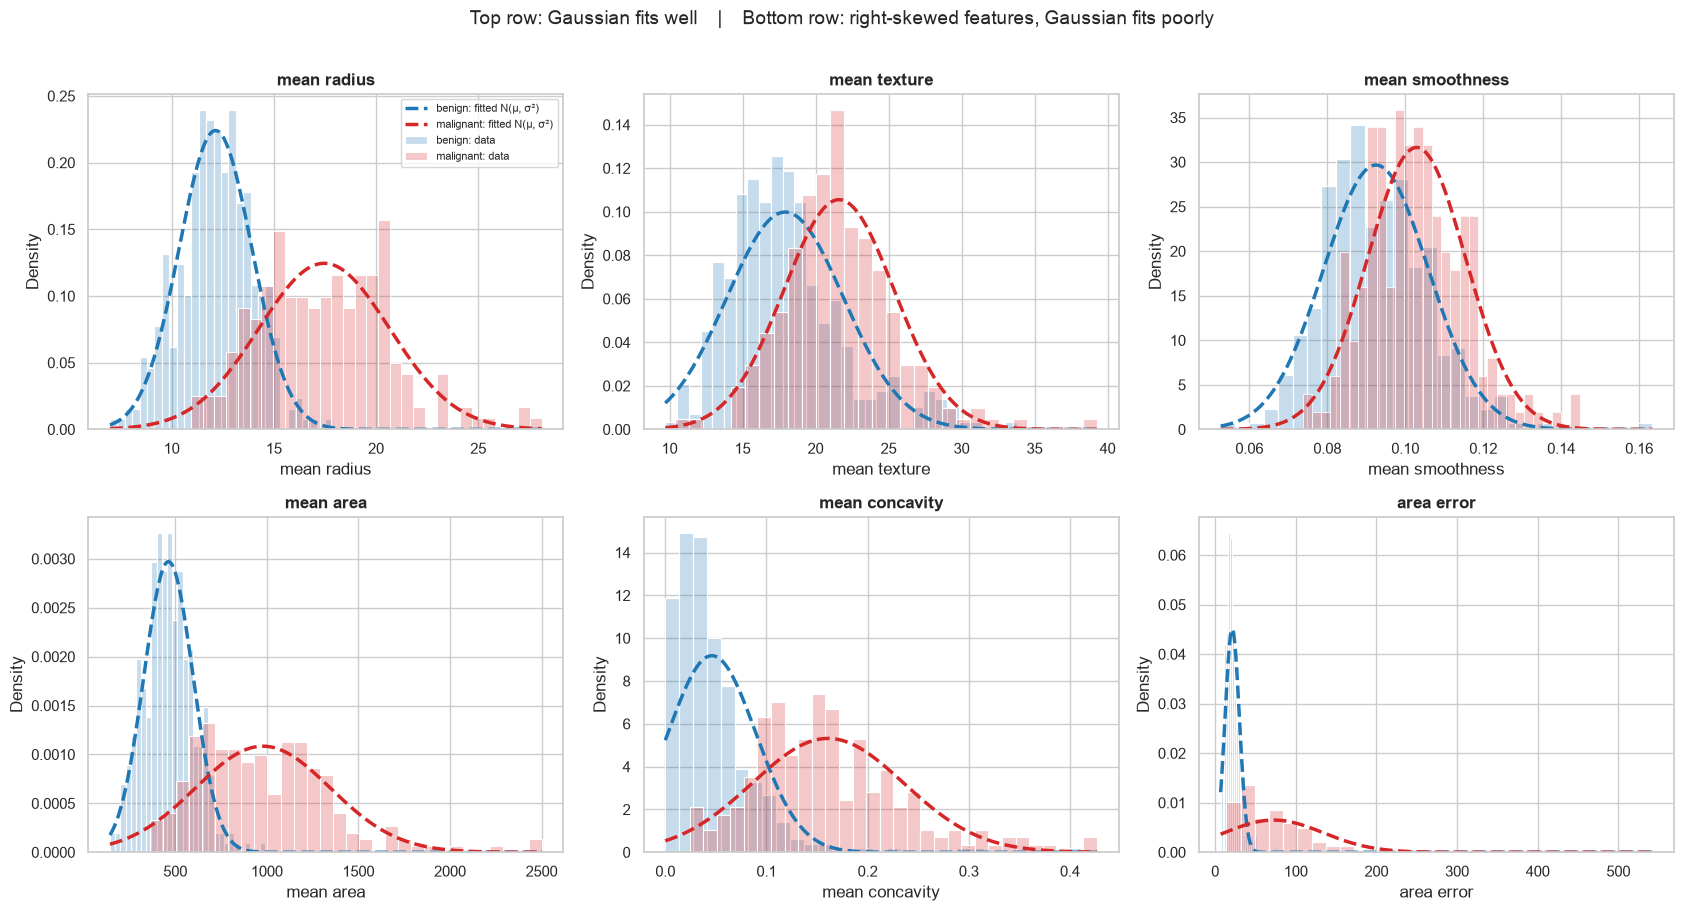

In [8]:
def plot_gaussian_fit(ax, frame, feat, bins=30):
    # Histogram of each class + the normal density GaussianNB would fit to it
    grid = np.linspace(frame[feat].min(), frame[feat].max(), 400)
    for label in CLASS_ORDER:
        x = frame.loc[frame["diagnosis"] == label, feat]
        sns.histplot(x, stat="density", bins=bins, color=PALETTE[label], alpha=0.25, ax=ax,
                     label=f"{label}: data")
        ax.plot(grid, stats.norm.pdf(grid, x.mean(), x.std()), color=PALETTE[label],
                lw=2.5, ls="--", label=f"{label}: fitted N(μ, σ²)")
    ax.set_title(feat, fontweight="bold")

fit_feats = focus + ["mean area", "mean concavity", "area error"]
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, feat in zip(axes.ravel(), fit_feats):
    plot_gaussian_fit(ax, df, feat)
axes[0, 0].legend(fontsize=8)
plt.suptitle("Top row: Gaussian fits well    |    Bottom row: right-skewed features, Gaussian fits poorly",
             y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

The top row supports the case-study premise: for radius, texture, and smoothness the normal curve is a reasonable description.

The bottom row tells a more nuanced story that a careful analyst must not skip:

- **`mean area`** is right-skewed. That makes sense physically: area grows with radius squared, so any skew in radius is amplified.
- **`mean concavity`** is strongly skewed and piles up near zero for benign tumors. The fitted Gaussian puts substantial probability on **negative concavity**, which is physically impossible.
- **`area error`** is extremely skewed with a long tail of outliers. The outliers inflate $\sigma$, so the fitted curve is too flat and too wide.

So the premise *"the features are approximately normal"* is **true for some features and false for others**. Let's see the full picture.

### 5.3 All 30 features at a glance

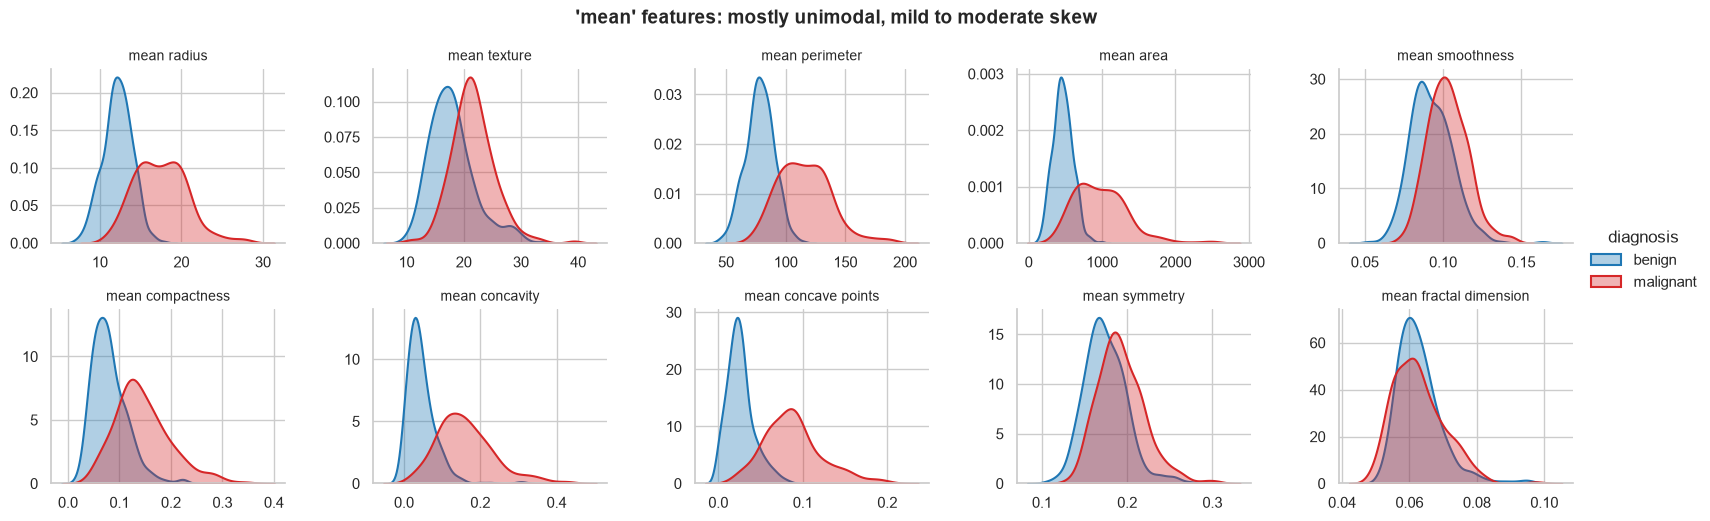

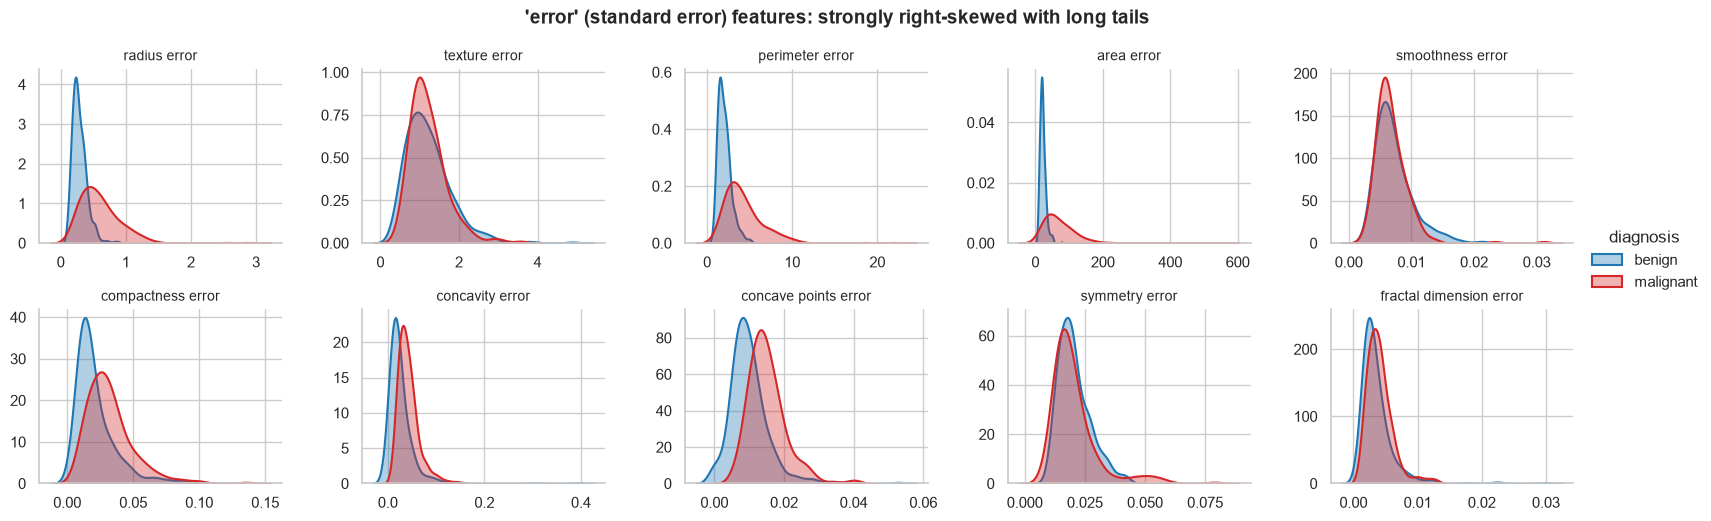

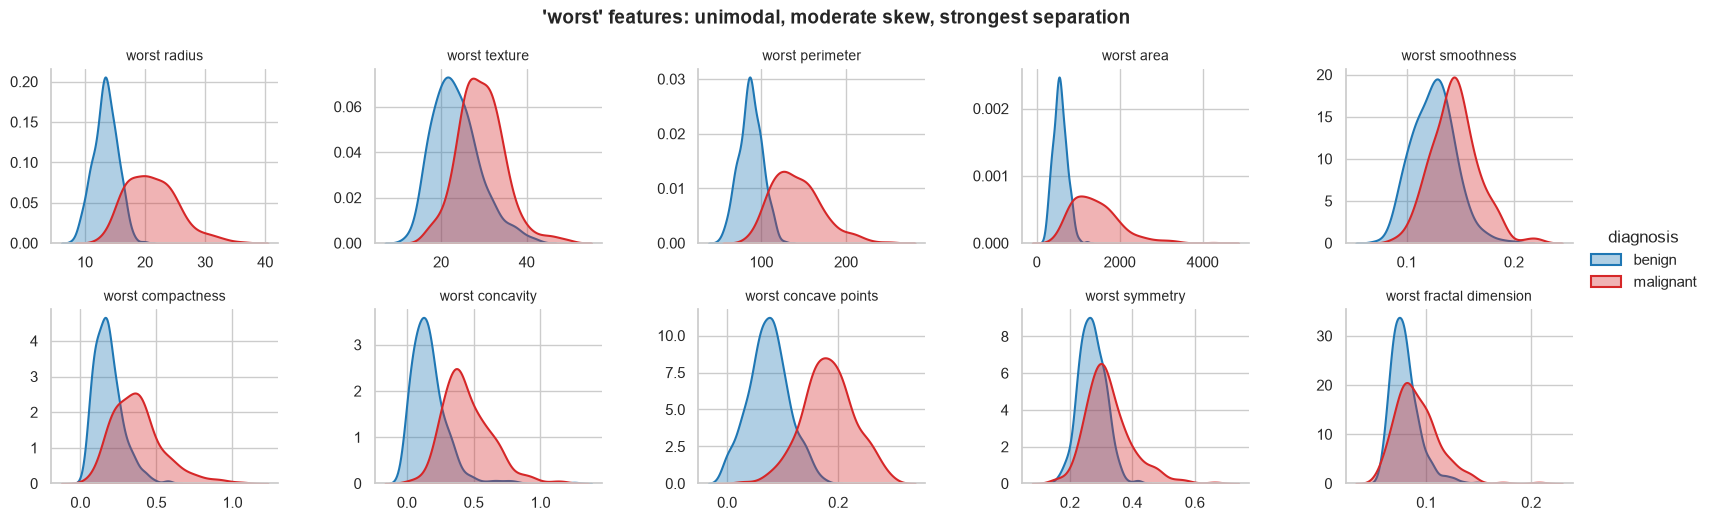

In [9]:
def kde_grid(feats, title):
    long = df.melt(id_vars="diagnosis", value_vars=feats, var_name="feature", value_name="value")
    g = sns.FacetGrid(long, col="feature", hue="diagnosis", hue_order=CLASS_ORDER, palette=PALETTE,
                      col_wrap=5, sharex=False, sharey=False, height=2.6, aspect=1.25)
    g.map(sns.kdeplot, "value", fill=True, alpha=0.35, linewidth=1.5, warn_singular=False)
    g.set_titles("{col_name}", size=10)
    g.set_axis_labels("", "")
    g.add_legend()
    g.figure.suptitle(title, y=1.04, fontsize=14, fontweight="bold")
    plt.show()

kde_grid(mean_feats,  "'mean' features: mostly unimodal, mild to moderate skew")
kde_grid(error_feats, "'error' (standard error) features: strongly right-skewed with long tails")
kde_grid(worst_feats, "'worst' features: unimodal, moderate skew, strongest separation")

The pattern is systematic and depends on the **type** of summary statistic:

- **mean** features: unimodal, mostly bell-like, with some right skew for size and concavity measurements.
- **error** features: standard errors are positive quantities with long right tails (a few images with very heterogeneous nuclei). These are the least Gaussian.
- **worst** features: unimodal, moderately skewed, and visibly the **most separated** between classes.

Encouragingly, nothing is clearly **bimodal within a class**. A single bell curve per class is a plausible shape everywhere; the main defect is **skewness**, which is fixable.

### 5.4 Quantifying normality: skewness, kurtosis

Eyeballing is useful but subjective, so we quantify it per feature *and per class* (normality must hold within each class, not for the pooled data).

In [10]:
rows = []
for feat in feature_names:
    for label in CLASS_ORDER:
        x = df.loc[df["diagnosis"] == label, feat]
        rows.append({
            "feature": feat,
            "class": label,
            "skewness": stats.skew(x),
            "excess_kurtosis": stats.kurtosis(x),
            "shapiro_p": stats.shapiro(x).pvalue,
        })
normality = pd.DataFrame(rows)

def shape_label(s):
    s = abs(s)
    return "≈ symmetric (|skew| < 0.5)" if s < 0.5 else ("moderate (0.5–1)" if s < 1 else "high (> 1)")

normality["shape"] = normality["skewness"].apply(shape_label)

print("Share of (feature, class) pairs with Shapiro–Wilk p < 0.05:",
      f"{(normality['shapiro_p'] < 0.05).mean():.0%}")
normality.pivot(index="feature", columns="class", values="skewness").loc[focus + ["mean area", "area error"]]

Share of (feature, class) pairs with Shapiro–Wilk p < 0.05: 90%


class,benign,malignant
feature,,
mean radius,-0.0834,0.4983
mean texture,0.9772,0.6986
mean smoothness,0.6607,0.4764
mean area,0.3408,1.1097
area error,1.6392,4.3142


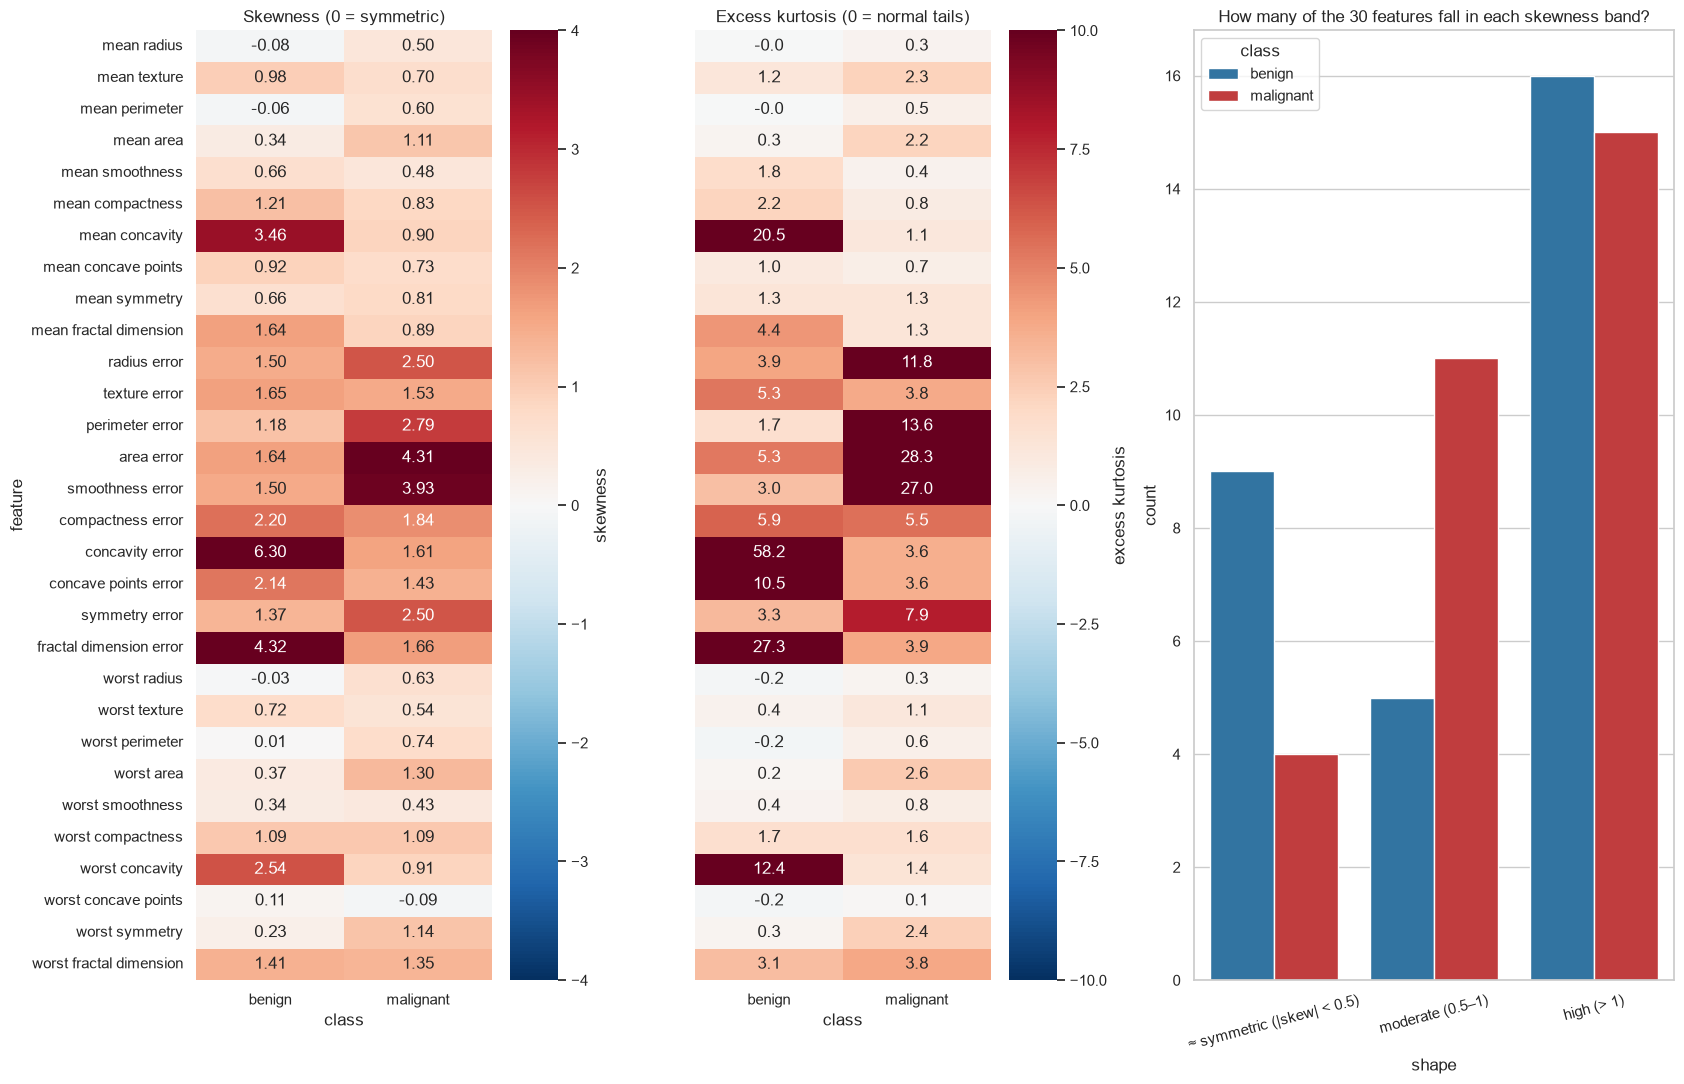

In [11]:
skew_pivot = normality.pivot(index="feature", columns="class", values="skewness").loc[feature_names, CLASS_ORDER]
kurt_pivot = normality.pivot(index="feature", columns="class", values="excess_kurtosis").loc[feature_names, CLASS_ORDER]

fig, axes = plt.subplots(1, 3, figsize=(17, 11), gridspec_kw={"width_ratios": [1, 1, 1.3]})
sns.heatmap(skew_pivot, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-4, vmax=4,
            cbar_kws={"label": "skewness"}, ax=axes[0])
axes[0].set_title("Skewness (0 = symmetric)")
sns.heatmap(kurt_pivot, annot=True, fmt=".1f", cmap="RdBu_r", center=0, vmin=-10, vmax=10,
            cbar_kws={"label": "excess kurtosis"}, ax=axes[1])
axes[1].set_title("Excess kurtosis (0 = normal tails)")
axes[1].set_yticklabels([])
axes[1].set_ylabel("")

shape_counts = normality.groupby(["class", "shape"]).size().reset_index(name="count")
sns.barplot(data=shape_counts, x="shape", y="count", hue="class", palette=PALETTE,
            order=["≈ symmetric (|skew| < 0.5)", "moderate (0.5–1)", "high (> 1)"], ax=axes[2])
axes[2].set_title("How many of the 30 features fall in each skewness band?")
axes[2].tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.show()

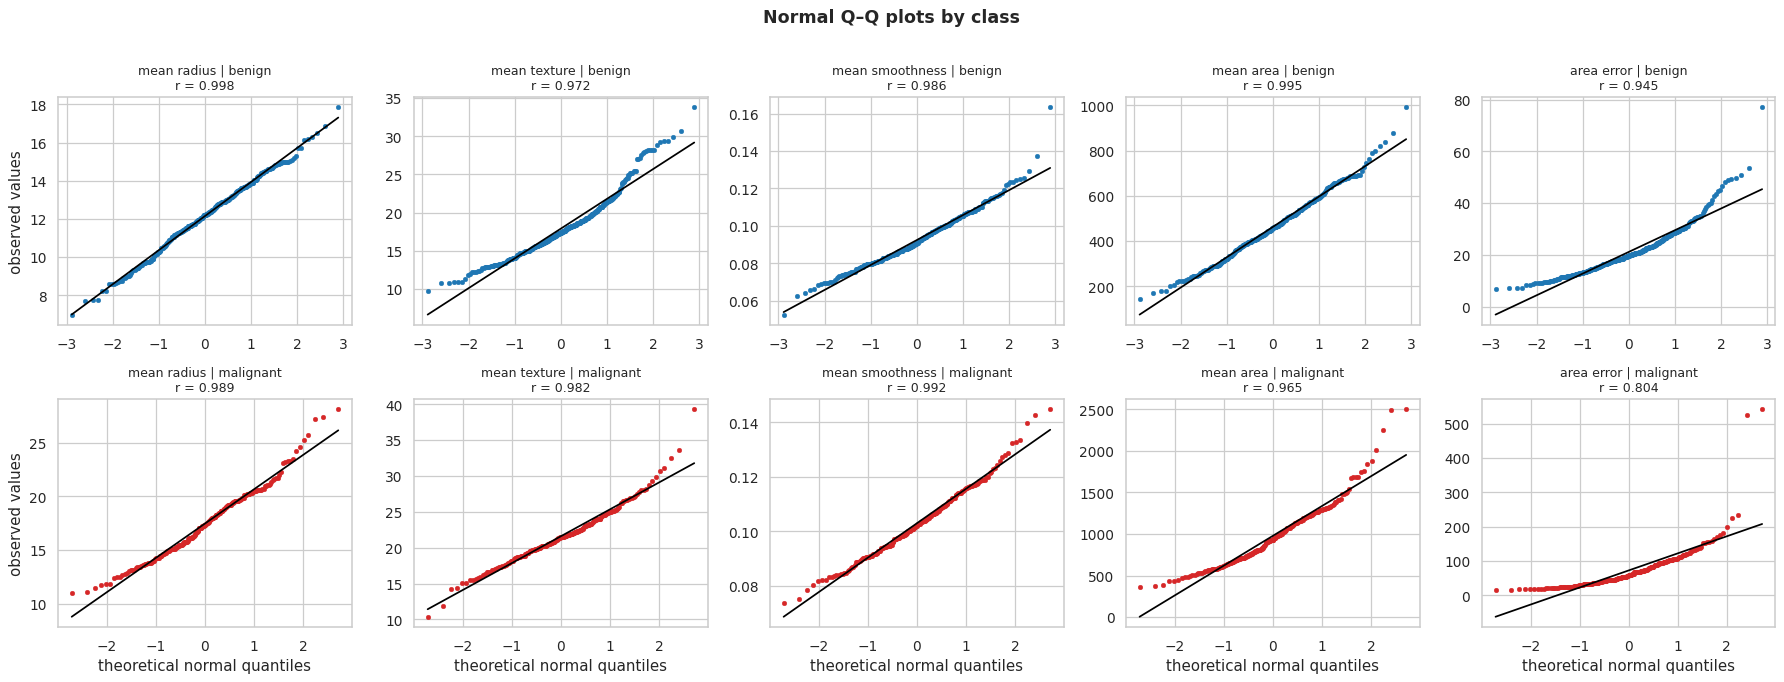

In [13]:
qq_feats = ["mean radius", "mean texture", "mean smoothness", "mean area", "area error"]

fig, axes = plt.subplots(2, len(qq_feats), figsize=(20, 7.5))
for j, feat in enumerate(qq_feats):
    for i, label in enumerate(CLASS_ORDER):
        ax = axes[i, j]
        x = df.loc[df["diagnosis"] == label, feat]
        (osm, osr), (slope, intercept, r) = stats.probplot(x, dist="norm")
        sns.scatterplot(x=osm, y=osr, ax=ax, color=PALETTE[label], s=14, edgecolor=None)
        ax.plot(osm, slope * osm + intercept, color="black", lw=1.4)
        ax.set_title(f"{feat} | {label}\nr = {r:.3f}", fontsize=10)
        ax.set_xlabel("theoretical normal quantiles" if i == 1 else "")
        ax.set_ylabel("observed values" if j == 0 else "")
plt.suptitle("Normal Q–Q plots by class", y=1.01, fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

Radius, texture and smoothness hug the line except in the extreme tails. `mean area` bends upward (right skew), and `area error` bends sharply: a classic long right tail.

**Q2 verdict ⚠️ : partially satisfied.** The Gaussian assumption is good for the concept features and acceptable for many others, but clearly violated by the skewed size, concavity and `error` features. Next we look at *why that matters* and what to do about it.


## Part 6: How distributions affect modeling choices

Distribution shape is not an academic detail; each deviation has a specific consequence for `GaussianNB` and a specific remedy:

| What we observe | What goes wrong in GaussianNB | Typical remedy |
|---|---|---|
| **Right skew** (area, error features) | Mean pulled into the tail, variance inflated; density too low at the peak, too high where no data lives (even at impossible negative values) | Log / Box–Cox / Yeo–Johnson transform |
| **Heavy tails / outliers** | A few extreme points inflate $\sigma$, flattening the curve and weakening the feature's evidence | Transform, robust clipping |
| **Exact zeros** (concavity) | `log(x)` and Box–Cox are undefined at 0 | `log1p`, or Yeo–Johnson (handles zero and negatives) |
| **Different variances per class** (radius: malignant wider) | Not a problem: GaussianNB fits $\sigma$ per class, giving *quadratic* boundaries. But see the artifact below | Nothing needed; be aware of extrapolation |
| **Bimodal within a class** | One bell can't describe two peaks | Kernel density NB, mixture models, or different model (not observed here) |
| **Features on wildly different scales** | In theory nothing. In practice `var_smoothing` interacts with scale (Part 9.2) | Standardize |

### 6.1 One feature, end to end: how the class-conditional Gaussians become a posterior

Let's fit `GaussianNB` on `mean radius` alone and plot $P(\text{malignant} \mid \text{radius})$. We deliberately extend the x-axis beyond the observed data.

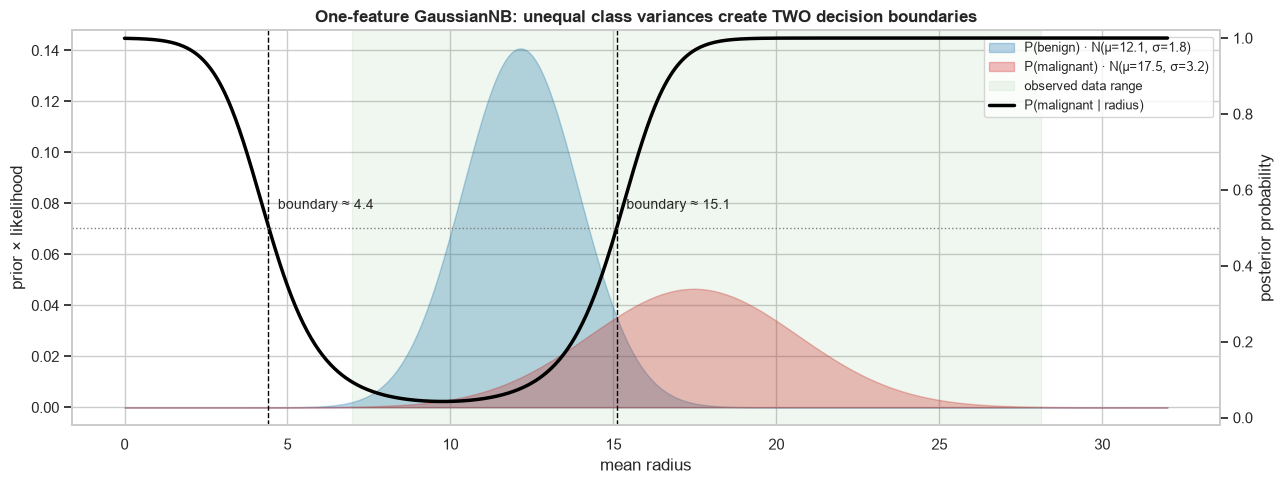

Decision boundaries (radius values where posterior = 0.5): [ 4.41 15.1 ]


In [12]:
feat = "mean radius"
nb_1d = GaussianNB().fit(df[[feat]], df["malignant"])
grid = np.linspace(0, 32, 800).reshape(-1, 1)
grid_df = pd.DataFrame(grid, columns=[feat])
posterior = nb_1d.predict_proba(grid_df)[:, 1]

mu, sd = nb_1d.theta_[:, 0], np.sqrt(nb_1d.var_[:, 0])
prior = nb_1d.class_prior_

fig, ax = plt.subplots(figsize=(13, 5))
for k, label in enumerate(CLASS_ORDER):                       # k=0 benign, k=1 malignant
    dens = prior[k] * stats.norm.pdf(grid.ravel(), mu[k], sd[k])
    ax.fill_between(grid.ravel(), dens, alpha=0.3, color=PALETTE[label],
                    label=f"P({label}) · N(μ={mu[k]:.1f}, σ={sd[k]:.1f})")
ax.set_xlabel(feat)
ax.set_ylabel("prior × likelihood")

ax2 = ax.twinx()
ax2.plot(grid, posterior, color="black", lw=2.5, label="P(malignant | radius)")
ax2.axhline(0.5, color="gray", ls=":", lw=1)
ax2.set_ylabel("posterior probability")
ax2.set_ylim(-0.02, 1.02)
ax2.grid(False)

crossings = grid.ravel()[np.where(np.diff(np.sign(posterior - 0.5)))[0]]
for c in crossings:
    ax.axvline(c, color="black", ls="--", lw=1)
    ax2.text(c + 0.3, 0.55, f"boundary ≈ {c:.1f}", fontsize=10)

ax.axvspan(df[feat].min(), df[feat].max(), color="green", alpha=0.06, label="observed data range")
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper right", fontsize=9)
ax.set_title("One-feature GaussianNB: unequal class variances create TWO decision boundaries",
             fontweight="bold")
plt.tight_layout()
plt.show()
print("Decision boundaries (radius values where posterior = 0.5):", np.round(crossings, 2))

This plot contains the whole mechanism of Gaussian Naive Bayes in one dimension, and it reveals two important effects of distribution shape:

1. **Unequal variances produce quadratic boundaries.** Because malignant radii are more spread out ($\sigma_M > \sigma_B$), the two weighted bell curves cross **twice**. The main boundary sits around a radius of 15: above it, the model says malignant.
2. **The Gaussian tails create an extrapolation artifact.** On the far left, the *wider* malignant curve decays more slowly than the narrow benign curve, so the posterior swings back up and a (physically implausible) tiny tumor is classified as **malignant**. No data supports this; it is purely an artifact of assuming Gaussian tails. In-range predictions are fine, but it is a concrete example of the assumption shaping predictions where data is absent.

### 6.2 Fixing skew with a power transform

For right-skewed positive data the classic fix is a log or Box–Cox transform. Box–Cox requires strictly positive values, but six concavity features contain exact zeros (Part 4), so we use **Yeo–Johnson**, a generalization that handles zero and negative values. `PowerTransformer` picks the transform strength $\lambda$ per feature by maximum likelihood (i.e., it searches for the transform that makes the column most Gaussian) and then standardizes.

> To avoid data leakage, in Part 9 the transformer is placed inside a `Pipeline` so it is fit only on training folds. Here we apply it to the full data *only for visualization*.

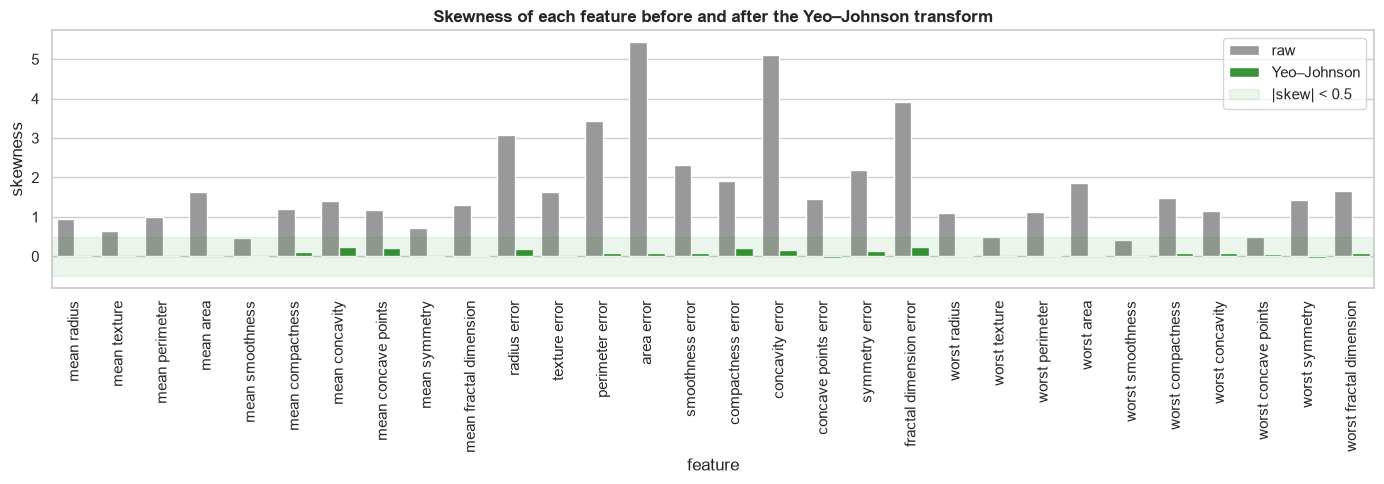

In [13]:
pt_vis = PowerTransformer(method="yeo-johnson")
df_yj = pd.DataFrame(pt_vis.fit_transform(df[feature_names]), columns=feature_names, index=df.index)
df_yj["diagnosis"] = df["diagnosis"]

skew_compare = pd.DataFrame({
    "feature": feature_names * 2,
    "skewness": [stats.skew(df[f]) for f in feature_names] + [stats.skew(df_yj[f]) for f in feature_names],
    "version": ["raw"] * 30 + ["Yeo–Johnson"] * 30,
})

fig, ax = plt.subplots(figsize=(14, 5))
sns.barplot(data=skew_compare, x="feature", y="skewness", hue="version",
            palette={"raw": "#999999", "Yeo–Johnson": "#2ca02c"}, ax=ax)
ax.axhspan(-0.5, 0.5, color="green", alpha=0.08, label="|skew| < 0.5")
ax.tick_params(axis="x", rotation=90)
ax.set_title("Skewness of each feature before and after the Yeo–Johnson transform", fontweight="bold")
ax.legend()
plt.tight_layout()
plt.show()

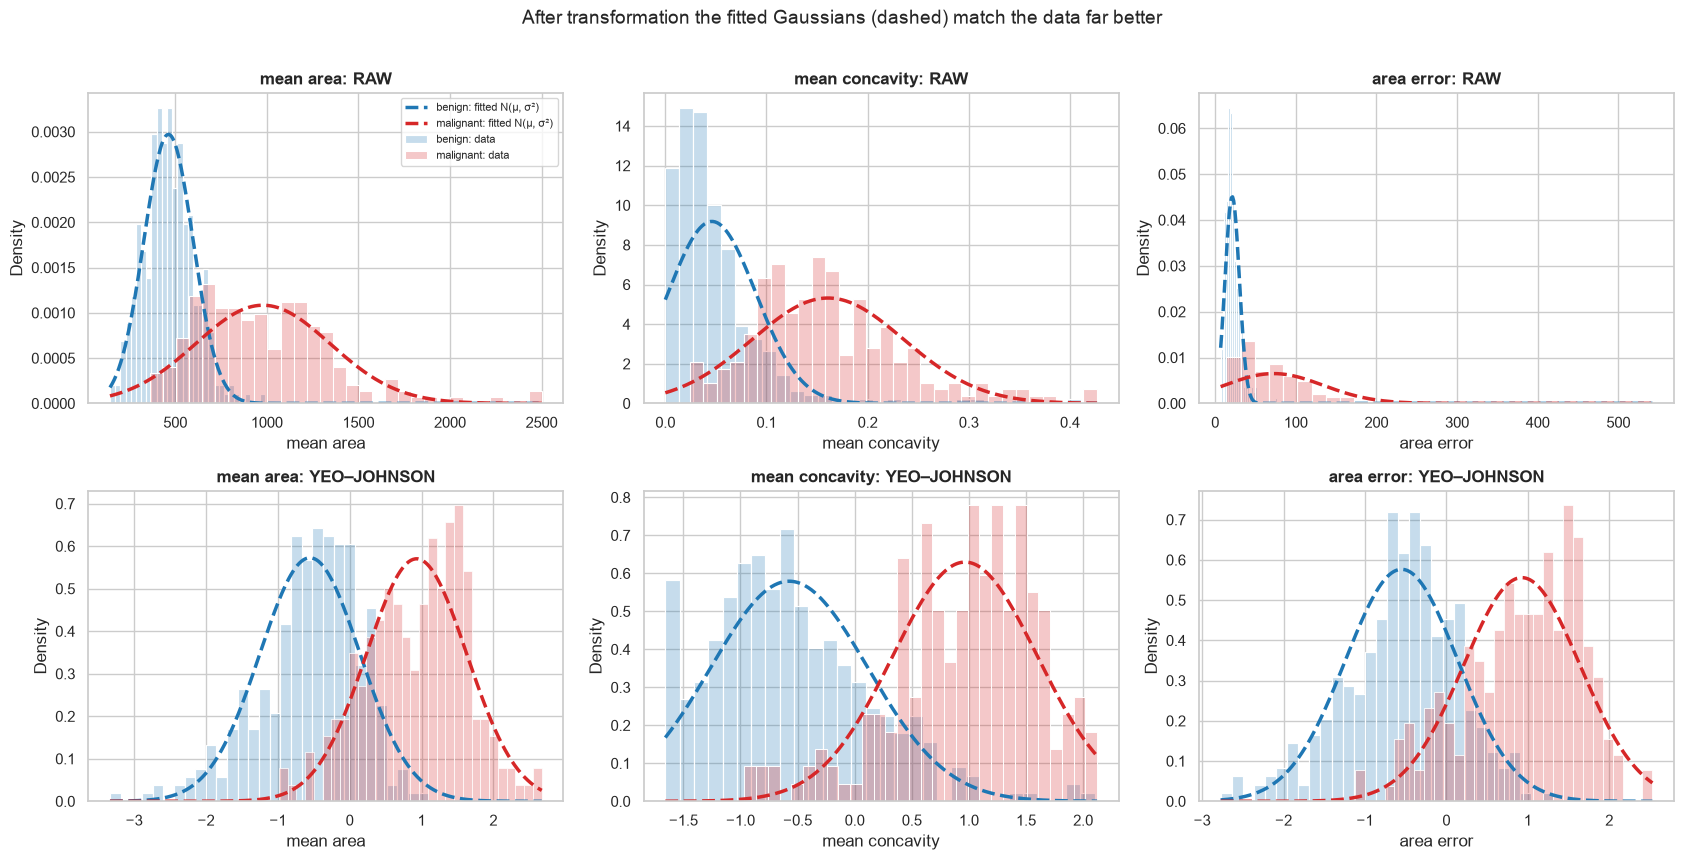

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8.5))
for j, feat in enumerate(["mean area", "mean concavity", "area error"]):
    plot_gaussian_fit(axes[0, j], df, feat)
    axes[0, j].set_title(f"{feat}: RAW", fontweight="bold")
    plot_gaussian_fit(axes[1, j], df_yj, feat)
    axes[1, j].set_title(f"{feat}: YEO–JOHNSON", fontweight="bold")
axes[0, 0].legend(fontsize=8)
plt.suptitle("After transformation the fitted Gaussians (dashed) match the data far better",
             y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

After the transform, the dashed normal curves trace the histograms much more closely and no probability mass is wasted on impossible values.

Whether this **improves classification** is a separate, empirical question that we answer in Part 9. Two cautions before we look:

- Classification only depends on *where the log-likelihood ratio changes sign*, so even a mis-shaped Gaussian can classify well. Better shapes may improve probabilities more than accuracy, or improve neither.
- `PowerTransformer` chooses $\lambda$ to make the **pooled** column (both classes mixed) look normal. Naive Bayes needs each class to be normal *separately*. Usually these go together, but not necessarily.

## Part 7 (Q3): Are the features conditionally independent?

This is the "naive" in Naive Bayes, and it is usually the most violated assumption. Recall the precise statement: **features must be independent within each class**. So we compute correlations separately for malignant and benign tumors.

### 7.1 Geometric redundancy: radius, perimeter, area

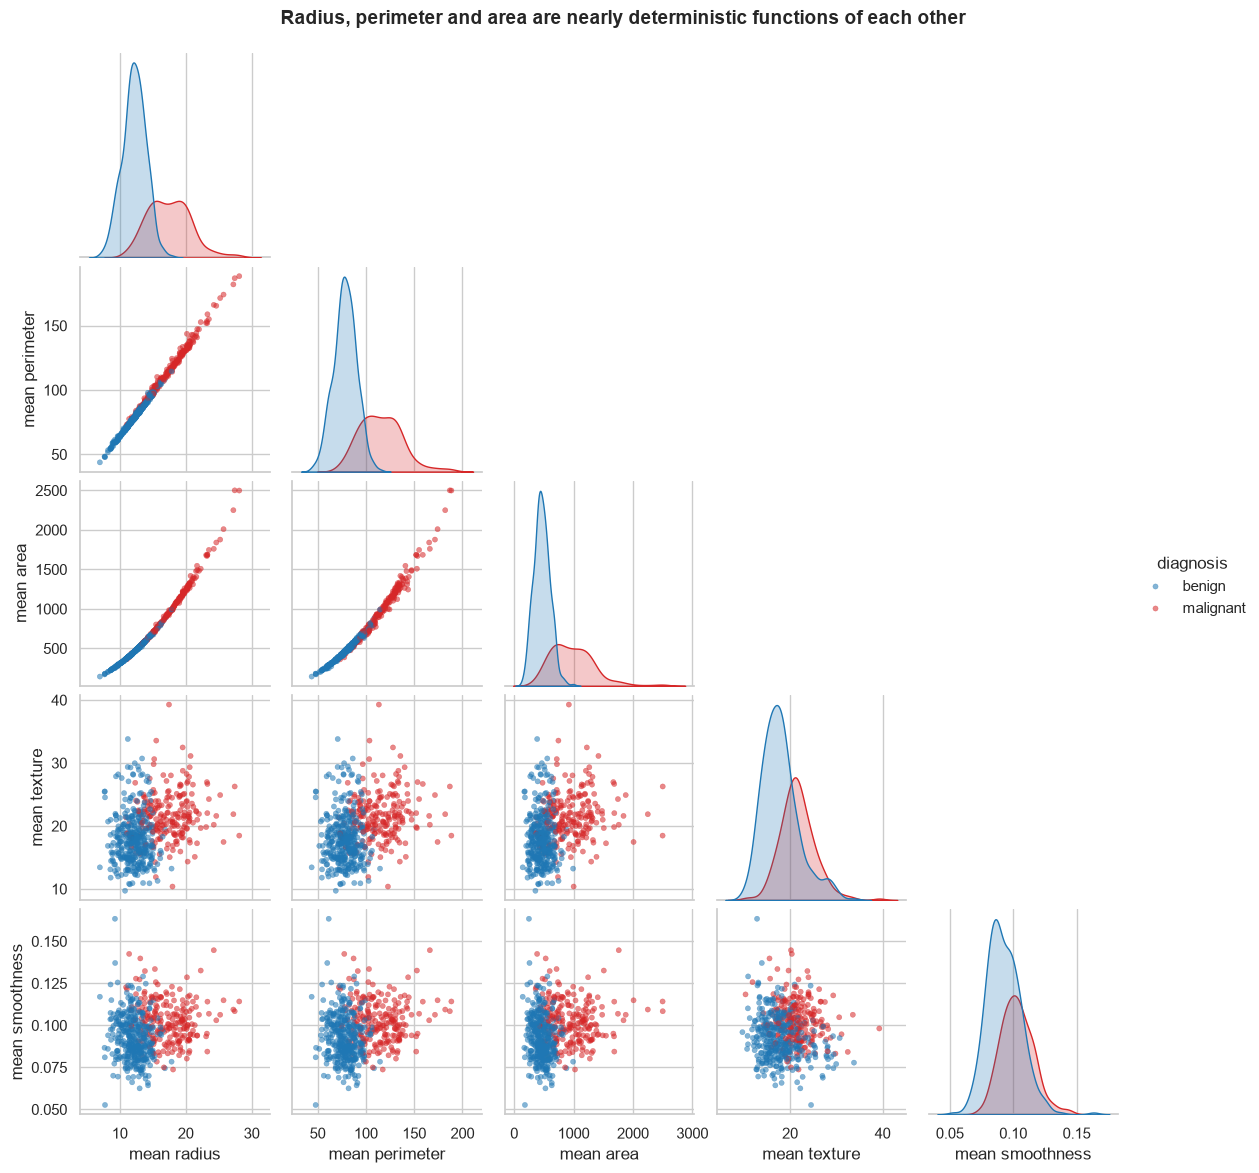

In [15]:
pair_feats = ["mean radius", "mean perimeter", "mean area", "mean texture", "mean smoothness"]
g = sns.pairplot(df[pair_feats + ["diagnosis"]], hue="diagnosis", hue_order=CLASS_ORDER,
                 palette=PALETTE, corner=True, diag_kind="kde", height=2.3,
                 plot_kws=dict(s=14, alpha=0.55, edgecolor=None))
g.figure.suptitle("Radius, perimeter and area are nearly deterministic functions of each other",
                  y=1.02, fontsize=14, fontweight="bold")
plt.show()

For a roughly circular nucleus, perimeter ≈ $2\pi r$ and area ≈ $\pi r^2$. Radius vs perimeter is a near-perfect line *within each class*, and radius vs area a tight curve. These three features carry essentially **one** piece of information. Texture and smoothness, by contrast, look like diffuse clouds against radius: much closer to independent.

### 7.2 Within-class correlation matrices

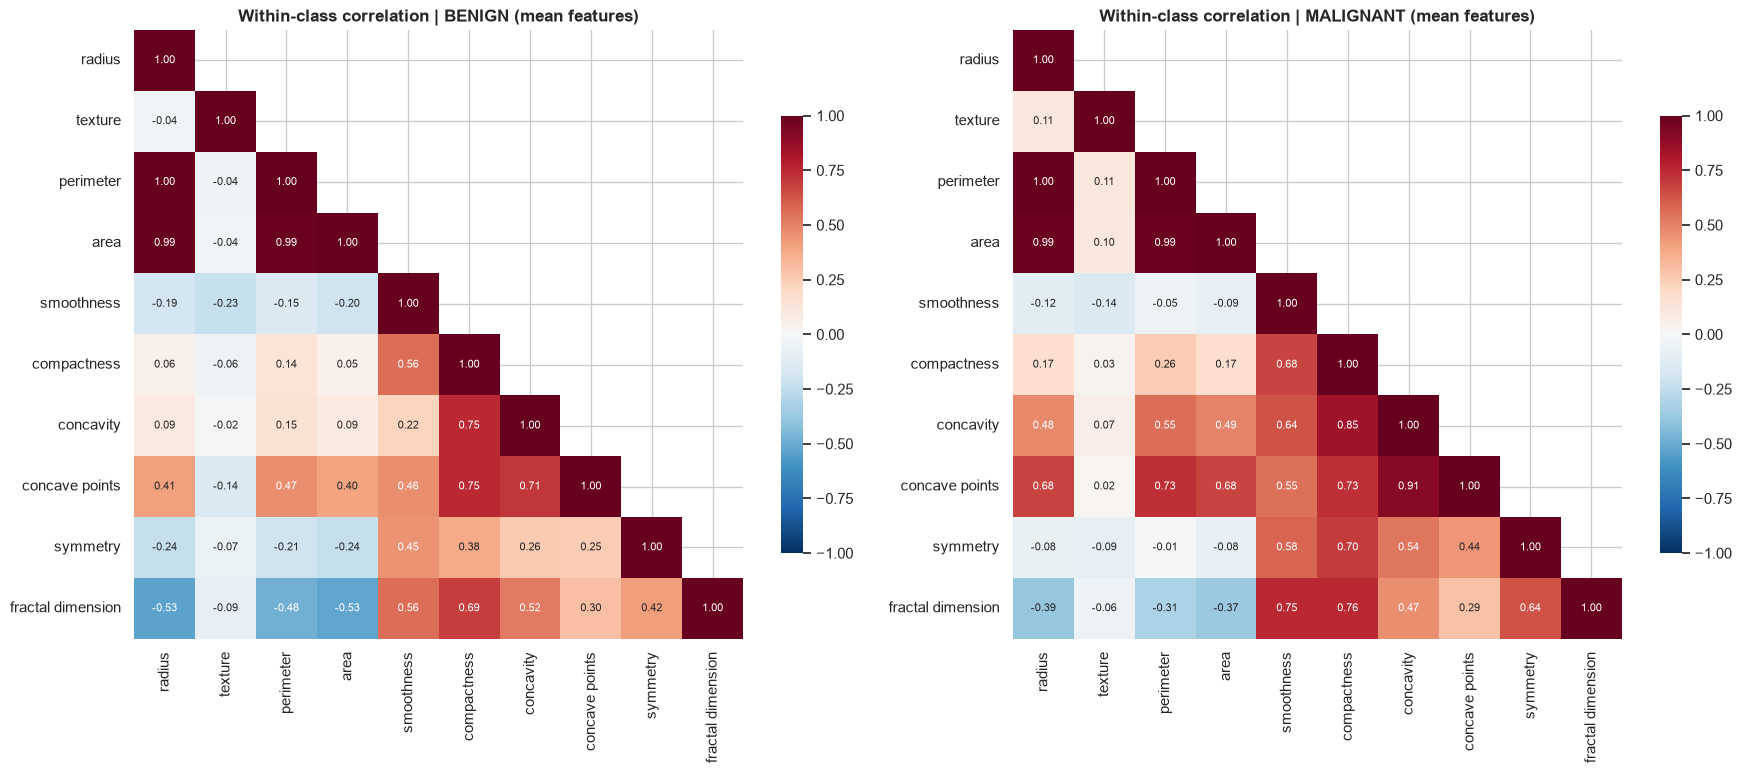

In [16]:
short = lambda cols: [c.replace("mean ", "") for c in cols]

fig, axes = plt.subplots(1, 2, figsize=(18, 7.5))
for ax, label in zip(axes, CLASS_ORDER):
    corr = df.loc[df["diagnosis"] == label, mean_feats].corr()
    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
    sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
                square=True, xticklabels=short(mean_feats), yticklabels=short(mean_feats),
                cbar_kws={"shrink": 0.7}, ax=ax, annot_kws={"size": 8})
    ax.set_title(f"Within-class correlation | {label.upper()} (mean features)", fontweight="bold")
plt.tight_layout()
plt.show()

In [17]:
def high_corr_pairs(frame, cols, threshold=0.9):
    corr = frame[cols].corr().abs()
    upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
    return upper[upper > threshold].sort_values(ascending=False)

summary_rows = []
for label in CLASS_ORDER:
    sub = df[df["diagnosis"] == label]
    abs_corr = sub[feature_names].corr().abs().values[np.triu_indices(30, k=1)]
    summary_rows.append({"class": label,
                         "pairs |r| > 0.9": int((abs_corr > 0.9).sum()),
                         "pairs |r| > 0.7": int((abs_corr > 0.7).sum()),
                         "median |r|": np.median(abs_corr)})
display(pd.DataFrame(summary_rows).set_index("class"))

print("Most redundant pairs within the MALIGNANT class:")
high_corr_pairs(df[df["diagnosis"] == "malignant"], feature_names).head(12).round(3)

,pairs |r| > 0.9,pairs |r| > 0.7,median |r|
class,,,
benign,19,43,0.2462
malignant,17,49,0.2632


Most redundant pairs within the MALIGNANT class:


mean radius      mean perimeter     0.995
                 mean area          0.990
mean perimeter   mean area          0.987
worst radius     worst area         0.986
                 worst perimeter    0.984
worst perimeter  worst area         0.971
radius error     perimeter error    0.970
                 area error         0.956
perimeter error  area error         0.933
mean perimeter   worst perimeter    0.922
mean radius      worst radius       0.922
mean area        worst radius       0.920
dtype: float64

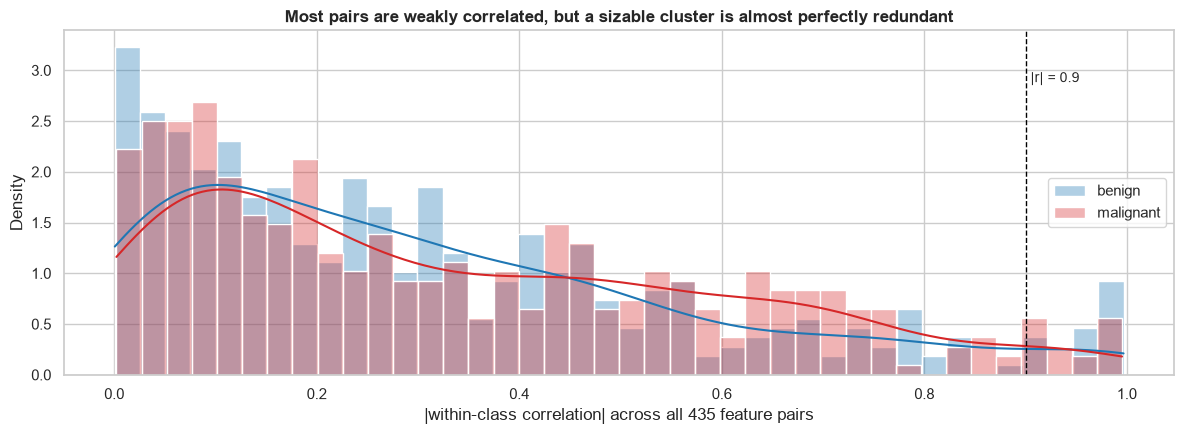

In [18]:
fig, ax = plt.subplots(figsize=(12, 4.5))
for label in CLASS_ORDER:
    sub = df.loc[df["diagnosis"] == label, feature_names].corr().abs().values
    vals = sub[np.triu_indices(30, k=1)]
    sns.histplot(vals, bins=40, stat="density", kde=True, color=PALETTE[label], alpha=0.35,
                 label=label, ax=ax)
ax.axvline(0.9, color="black", ls="--", lw=1)
ax.text(0.905, ax.get_ylim()[1] * 0.85, "|r| = 0.9", fontsize=10)
ax.set_xlabel("|within-class correlation| across all 435 feature pairs")
ax.set_title("Most pairs are weakly correlated, but a sizable cluster is almost perfectly redundant",
             fontweight="bold")
ax.legend()
plt.tight_layout()
plt.show()

### 7.3 Visualizing the independence assumption directly

`GaussianNB`'s class-conditional density in 2-D is a product of two 1-D Gaussians, so its contours are **axis-aligned ellipses**: they cannot tilt. On the left (radius vs texture) that's a reasonable description. On the right (radius vs perimeter) the real data lies on a thin diagonal line while the model imagines a broad axis-aligned blob.

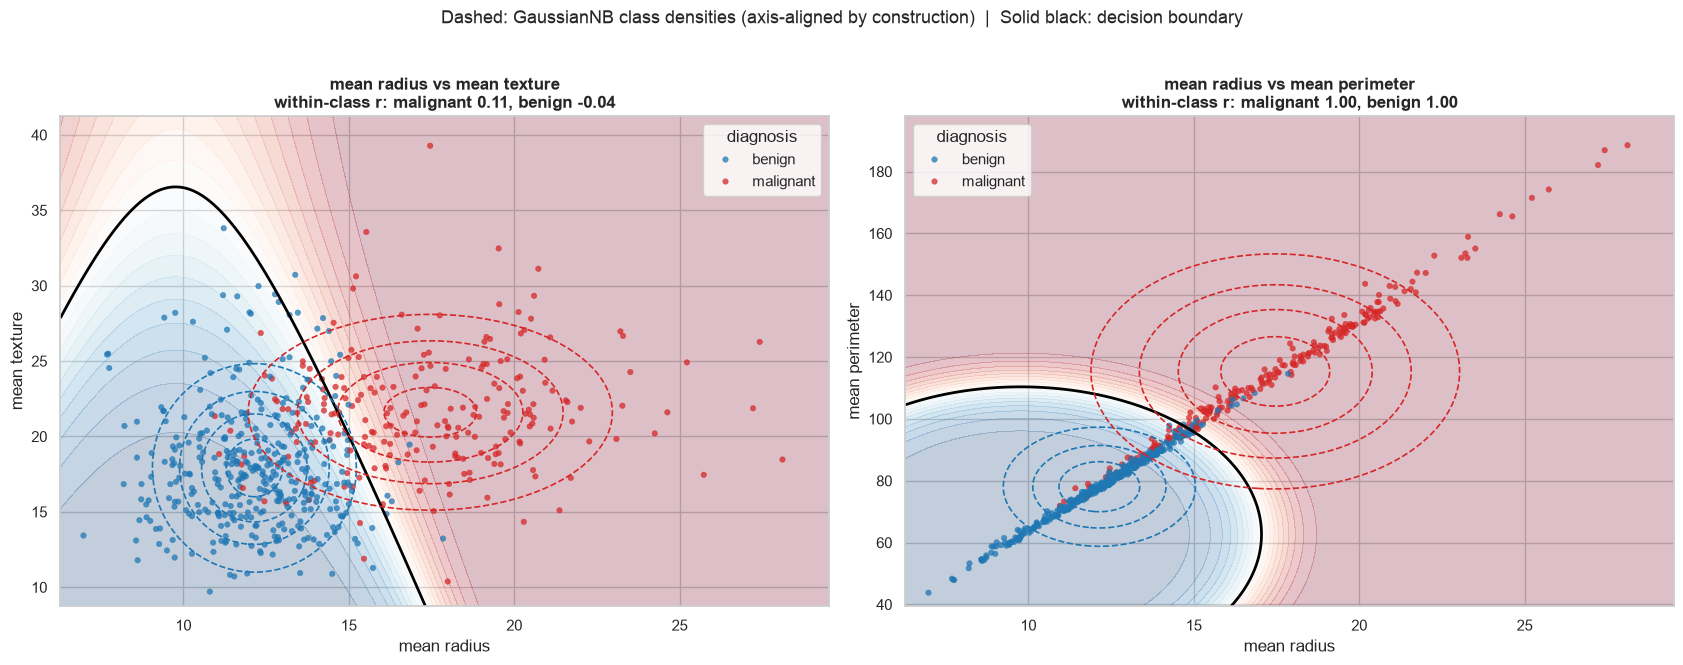

In [19]:
def nb_2d_panel(ax, fx, fy):
    X2 = df[[fx, fy]]
    nb2 = GaussianNB().fit(X2, df["malignant"])
    xs = np.linspace(X2[fx].min() * 0.9, X2[fx].max() * 1.05, 300)
    ys = np.linspace(X2[fy].min() * 0.9, X2[fy].max() * 1.05, 300)
    XX, YY = np.meshgrid(xs, ys)
    grid2 = pd.DataFrame(np.c_[XX.ravel(), YY.ravel()], columns=[fx, fy])
    P = nb2.predict_proba(grid2)[:, 1].reshape(XX.shape)

    ax.contourf(XX, YY, P, levels=np.linspace(0, 1, 21), cmap="RdBu_r", alpha=0.25)
    ax.contour(XX, YY, P, levels=[0.5], colors="black", linewidths=2)
    for k, label in enumerate(CLASS_ORDER):
        dens = (stats.norm.pdf(XX, nb2.theta_[k, 0], np.sqrt(nb2.var_[k, 0])) *
                stats.norm.pdf(YY, nb2.theta_[k, 1], np.sqrt(nb2.var_[k, 1])))
        ax.contour(XX, YY, dens, levels=4, colors=PALETTE[label], linewidths=1.2, linestyles="--")
    sns.scatterplot(data=df, x=fx, y=fy, hue="diagnosis", hue_order=CLASS_ORDER, palette=PALETTE,
                    s=16, alpha=0.75, edgecolor=None, ax=ax)
    r_m = df.loc[df.diagnosis == "malignant", [fx, fy]].corr().iloc[0, 1]
    r_b = df.loc[df.diagnosis == "benign", [fx, fy]].corr().iloc[0, 1]
    ax.set_title(f"{fx} vs {fy}\nwithin-class r: malignant {r_m:.2f}, benign {r_b:.2f}", fontweight="bold")

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
nb_2d_panel(axes[0], "mean radius", "mean texture")
nb_2d_panel(axes[1], "mean radius", "mean perimeter")
plt.suptitle("Dashed: GaussianNB class densities (axis-aligned by construction)  |  Solid black: decision boundary",
             y=1.02, fontsize=13)
plt.tight_layout()
plt.show()

### 7.4 Why violations matter (and why NB often survives them)

When features are redundant, Naive Bayes **counts the same evidence several times**. A large tumor contributes evidence through `radius`, `perimeter`, `area`, `worst radius`, `worst perimeter`, `worst area`... six times for one underlying fact. Consequences:

- **Probabilities become overconfident**, pushed toward 0 and 1 (we verify this in Part 10).
- **Classification accuracy is often surprisingly unharmed.** Double counting stretches the log-odds but frequently doesn't change their *sign*. Domingos & Pazzani (1997) showed that Naive Bayes can be optimal under 0–1 loss even when independence is badly violated.

Remedies we will test: **drop redundant features** (keep one per correlated group), or correct the probabilities with **calibration**.

**Q3 verdict: violated for a cluster of size-related features, roughly satisfied for the rest.** Expect good rankings and overconfident probabilities.

## Part 8 (Q4): Does each feature separate the classes?

Naive Bayes builds its decision from **univariate** evidence. If a feature only matters in combination with another (an interaction, like XOR), NB cannot use it. So we want features that individually differ between classes.

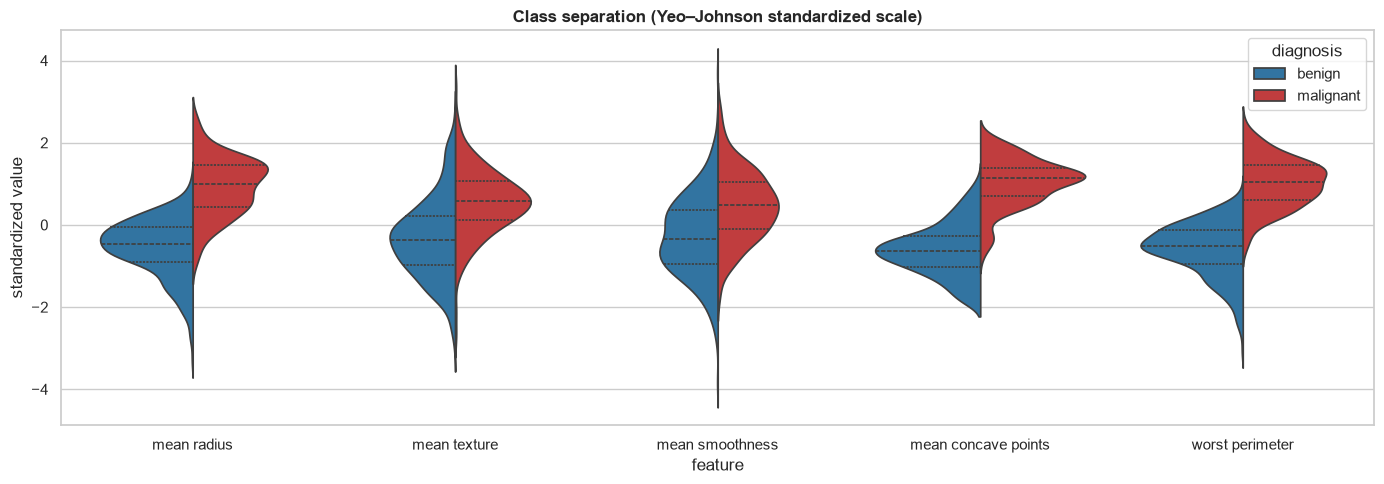

In [20]:
long_focus = df_yj.melt(id_vars="diagnosis", value_vars=focus + ["mean concave points", "worst perimeter"],
                        var_name="feature", value_name="standardized value")
fig, ax = plt.subplots(figsize=(14, 5))
sns.violinplot(data=long_focus, x="feature", y="standardized value", hue="diagnosis",
               hue_order=CLASS_ORDER, palette=PALETTE, split=True, inner="quart", ax=ax)
ax.set_title("Class separation (Yeo–Johnson standardized scale)", fontweight="bold")
plt.tight_layout()
plt.show()

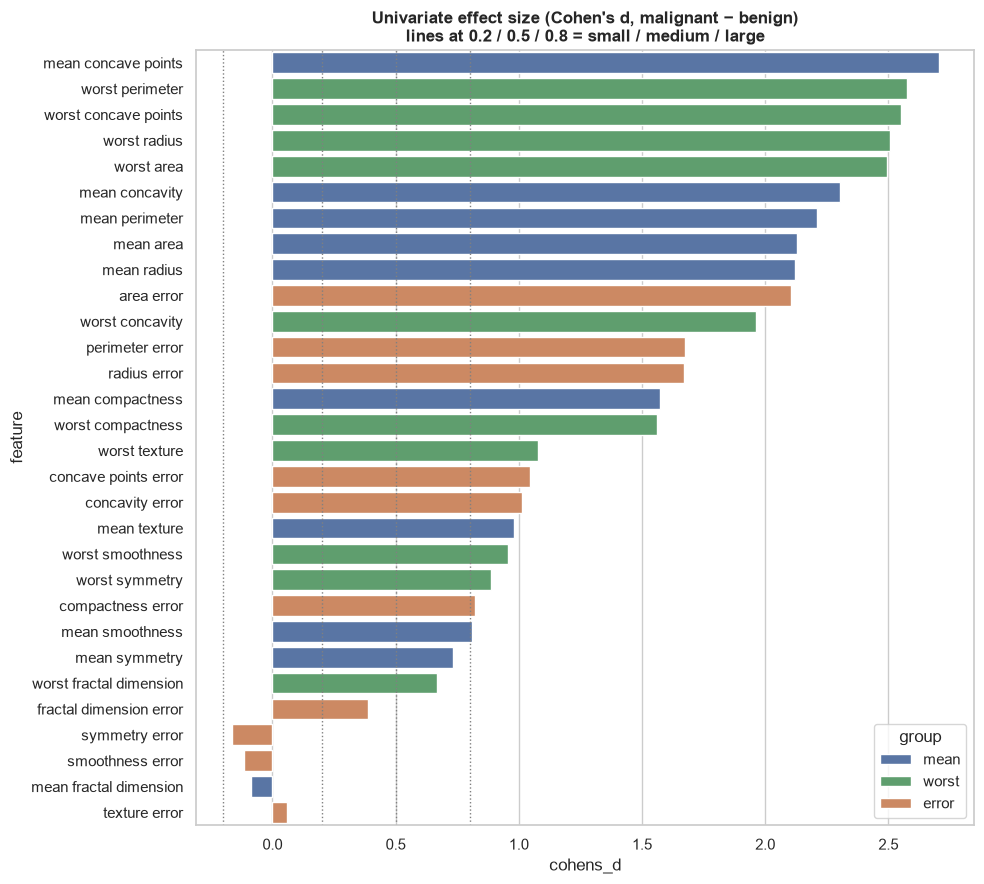

In [21]:
def cohens_d(a, b):
    na, nb = len(a), len(b)
    pooled = np.sqrt(((na - 1) * a.var(ddof=1) + (nb - 1) * b.var(ddof=1)) / (na + nb - 2))
    return (a.mean() - b.mean()) / pooled

effect = pd.DataFrame({
    "feature": feature_names,
    "cohens_d": [cohens_d(df_yj.loc[df.malignant == 1, f], df_yj.loc[df.malignant == 0, f]) for f in feature_names],
    "group": ["mean"] * 10 + ["error"] * 10 + ["worst"] * 10,
}).sort_values("cohens_d", key=abs, ascending=False)

fig, ax = plt.subplots(figsize=(10, 9))
sns.barplot(data=effect, y="feature", x="cohens_d", hue="group",
            palette={"mean": "#4c72b0", "error": "#dd8452", "worst": "#55a868"}, dodge=False, ax=ax)
for x in (0.2, 0.5, 0.8):
    ax.axvline(x, color="gray", ls=":", lw=1)
ax.axvline(-0.2, color="gray", ls=":", lw=1)
ax.set_title("Univariate effect size (Cohen's d, malignant − benign)\nlines at 0.2 / 0.5 / 0.8 = small / medium / large",
             fontweight="bold")
plt.tight_layout()
plt.show()

**Q4 verdict: strongly satisfied.** Many features have enormous univariate effect sizes ($d > 2$, i.e., the class means are more than two pooled standard deviations apart) for the concave points, concavity, perimeter, radius and area features. Among our concept features, radius is in that top group, while texture and smoothness are clearly useful ($d \approx 0.8$–$1$) but much weaker. A handful of features (`texture error`, `smoothness error`, `symmetry error`, `fractal dimension error`, `mean fractal dimension`) carry almost no signal; for Naive Bayes they mostly add noise to the sum of evidence. This is a favourable situation for Naive Bayes: the signal is mostly *additive* and *univariate*, exactly what the model is built to combine.

## Part 9: Building and validating the model

### 9.1 Train/test split

We hold out 25% of the data as a **final test set** that we touch only once, at the end (Part 12). All design decisions (which features, which transform, which threshold) are made using **cross-validation on the training set only**. This prevents us from tuning to the test set and fooling ourselves.

In [22]:
X = df[feature_names]
y = df["malignant"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)

print(f"Train: {X_train.shape[0]} samples ({y_train.mean():.1%} malignant)")
print(f"Test : {X_test.shape[0]} samples ({y_test.mean():.1%} malignant)")

Train: 426 samples (37.3% malignant)
Test : 143 samples (37.1% malignant)


### 9.2 The baseline model and what it learned

In [23]:
gnb = GaussianNB().fit(X_train, y_train)

print("classes_     :", gnb.classes_, " (0 = benign, 1 = malignant)")
print("class_prior_ :", gnb.class_prior_.round(3))
print("epsilon_ (variance added to every feature by var_smoothing):", f"{gnb.epsilon_:.2e}")

learned = pd.DataFrame({
    "μ benign": gnb.theta_[0], "σ benign": np.sqrt(gnb.var_[0]),
    "μ malignant": gnb.theta_[1], "σ malignant": np.sqrt(gnb.var_[1]),
    "true var (benign)": X_train[y_train == 0].var(ddof=0).values,
    "var used (benign)": gnb.var_[0],
}, index=feature_names)
learned["var inflation (benign)"] = learned["var used (benign)"] / learned["true var (benign)"]
learned.sort_values("var inflation (benign)", ascending=False).head(10)

classes_     : [0 1]  (0 = benign, 1 = malignant)
class_prior_ : [0.627 0.373]
epsilon_ (variance added to every feature by var_smoothing): 3.45e-04


,μ benign,σ benign,μ malignant,σ malignant,true var (benign),var used (benign),var inflation (benign)
smoothness error,0.0070,0.0188,0.0067,0.0188,7.4772e-06,0.0004,47.0844
fractal dimension error,0.0037,0.0188,0.0039,0.0187,9.0662e-06,0.0004,39.0073
concave points error,0.0098,0.0194,0.0147,0.0194,3.3668e-05,0.0004,11.2346
symmetry error,0.0203,0.0197,0.0203,0.0214,4.3720e-05,0.0004,8.8816
mean fractal dimension,0.0627,0.0197,0.0624,0.0201,4.4973e-05,0.0004,8.6620
mean smoothness,0.0918,0.0229,0.1030,0.0228,1.7854e-04,0.0005,2.9300
worst fractal dimension,0.0798,0.0234,0.0906,0.0280,2.0274e-04,0.0005,2.6996
mean concave points,0.0256,0.0243,0.0881,0.0402,2.4471e-04,0.0006,2.4081
compactness error,0.0216,0.0249,0.0308,0.0255,2.7774e-04,0.0006,2.2407
worst smoothness,0.1245,0.0275,0.1453,0.0293,4.1384e-04,0.0008,1.8326


**A subtle gotcha revealed by inspecting the parameters.** The parameter table should simply contain each class's mean and variance... but look at the last column. `GaussianNB` adds a small constant to every variance for numerical stability:

$$\varepsilon = \texttt{var\_smoothing} \times \max_i \operatorname{Var}(x_i) = 10^{-9} \times \operatorname{Var}(\text{worst area}).$$

Because `worst area` has a variance in the hundreds of thousands, $\varepsilon$ is not "tiny" relative to features like `smoothness error` or `fractal dimension error`, whose variances are around $10^{-5}$. Their variances are inflated **many-fold**, flattening their Gaussians and silencing their evidence.

So the textbook claim *"Naive Bayes doesn't need feature scaling"* is true for the mathematical model but **not quite true for scikit-learn's implementation on this dataset**. Let's measure whether it matters.

In [24]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=RANDOM_STATE)
scoring = {"accuracy": "accuracy", "recall (malignant)": "recall", "precision (malignant)": "precision",
           "ROC AUC": "roc_auc", "log loss": "neg_log_loss", "Brier score": "neg_brier_score"}
LOWER_IS_BETTER = {"log loss", "Brier score"}

def cv_compare(models, X_, y_, cv=cv):
    # models: {name: (estimator, feature_list)}; returns long-form per-fold results
    rows = []
    for name, (est, cols) in models.items():
        res = cross_validate(est, X_[cols], y_, cv=cv, scoring=scoring)
        for metric in scoring:
            vals = res[f"test_{metric}"]
            vals = -vals if metric in LOWER_IS_BETTER else vals
            rows += [{"model": name, "metric": metric, "score": v} for v in vals]
    return pd.DataFrame(rows)

def summarize(results):
    return (results.groupby(["model", "metric"], sort=False)["score"]
            .agg(lambda s: f"{s.mean():.3f} ± {s.std():.3f}").unstack()[list(scoring)])

scaling_models = {
    "GNB raw (default var_smoothing)":   (GaussianNB(), feature_names),
    "GNB raw (var_smoothing=1e-15)":     (GaussianNB(var_smoothing=1e-15), feature_names),
    "GNB standardized":                  (make_pipeline(StandardScaler(), GaussianNB()), feature_names),
}
scaling_results = cv_compare(scaling_models, X_train, y_train)
summarize(scaling_results)

metric,accuracy,recall (malignant),precision (malignant),ROC AUC,log loss,Brier score
model,,,,,,
GNB raw (default var_smoothing),0.941 ± 0.021,0.896 ± 0.050,0.945 ± 0.040,0.985 ± 0.011,0.668 ± 0.383,0.056 ± 0.020
GNB raw (var_smoothing=1e-15),0.940 ± 0.023,0.899 ± 0.050,0.939 ± 0.038,0.986 ± 0.011,0.621 ± 0.358,0.057 ± 0.021
GNB standardized,0.940 ± 0.023,0.899 ± 0.050,0.939 ± 0.038,0.986 ± 0.011,0.621 ± 0.358,0.057 ± 0.021


Standardizing and turning `var_smoothing` down give **identical** results, as theory predicts: both remove the distortion. Compared with the default raw model the difference is small here (accuracy is unchanged to within 0.001; log loss improves a little). The gotcha is mostly harmless on this dataset because the features whose variances were inflated the most (`smoothness error`, `fractal dimension error`, ...) are exactly the ones with almost no signal (Part 8). On a different dataset where a tiny-variance feature *is* important, the same default could silently disable it.

Standardizing costs nothing and removes a hidden dependence on measurement units, so **from here on every Gaussian NB model is standardized** (`PowerTransformer` standardizes by default too).

### 9.3 Testing our design choices with cross-validation

Parts 4–8 produced concrete hypotheses. Now we test them:

| Model | Hypothesis being tested |
|---|---|
| GNB · 3 concept features | Do radius, texture, smoothness alone suffice? |
| GNB · 10 mean features | Is one summary per measurement enough? |
| GNB · all 30 | Baseline with everything (standardized) |
| GNB · all 30 + Yeo–Johnson | Does fixing skew help? (Part 6) |
| GNB · decorrelated (column order) | Does naively removing redundant features help? (Part 7) |
| GNB · decorrelated (best-first) | Does *careful* removal help? |
| GNB · decorrelated (best-first) + YJ | Both fixes together |
| BernoulliNB · binarized | What does the wrong variant cost? (Part 4) |
| MultinomialNB · min–max | What does the wrong variant cost? (Part 4) |

**Two ways to remove redundancy.** A greedy filter walks through the features and drops any feature correlated above a threshold with one already kept. *Which* feature survives depends on the walking order:

- **column order** keeps whatever comes first (`mean radius` survives, `worst perimeter` is dropped),
- **best-first** order ranks features by univariate effect size first, so the *most discriminative* member of each redundant group survives.

Both rankings and correlations are computed **on the training set only**.

In [25]:
def drop_correlated(frame, ranked_cols, threshold):
    # Greedy filter: walk through ranked_cols, keep a feature only if |r| <= threshold with all kept ones
    corr = frame[ranked_cols].corr().abs()
    keep = []
    for col in ranked_cols:
        if all(corr.loc[col, k] <= threshold for k in keep):
            keep.append(col)
    return keep

# Univariate signal of each feature, measured on the TRAINING set only
d_train = pd.Series({f: abs(cohens_d(X_train.loc[y_train == 1, f], X_train.loc[y_train == 0, f]))
                     for f in feature_names}).sort_values(ascending=False)

decor_naive = drop_correlated(X_train, feature_names, threshold=0.9)         # column order
decor_best  = drop_correlated(X_train, list(d_train.index), threshold=0.8)   # best-first order

print(f"Column-order filter (|r| <= 0.9): kept {len(decor_naive)}; dropped",
      [f for f in feature_names if f not in decor_naive])
print(f"\nBest-first filter  (|r| <= 0.8): kept {len(decor_best)}:", decor_best)

Column-order filter (|r| <= 0.9): kept 21; dropped [np.str_('mean perimeter'), np.str_('mean area'), np.str_('mean concave points'), np.str_('perimeter error'), np.str_('area error'), np.str_('worst radius'), np.str_('worst texture'), np.str_('worst perimeter'), np.str_('worst area')]

Best-first filter  (|r| <= 0.8): kept 15: ['worst concave points', 'worst radius', 'radius error', 'worst texture', 'worst smoothness', 'worst symmetry', 'concave points error', 'mean symmetry', 'worst fractal dimension', 'compactness error', 'smoothness error', 'fractal dimension error', 'texture error', 'mean fractal dimension', 'symmetry error']


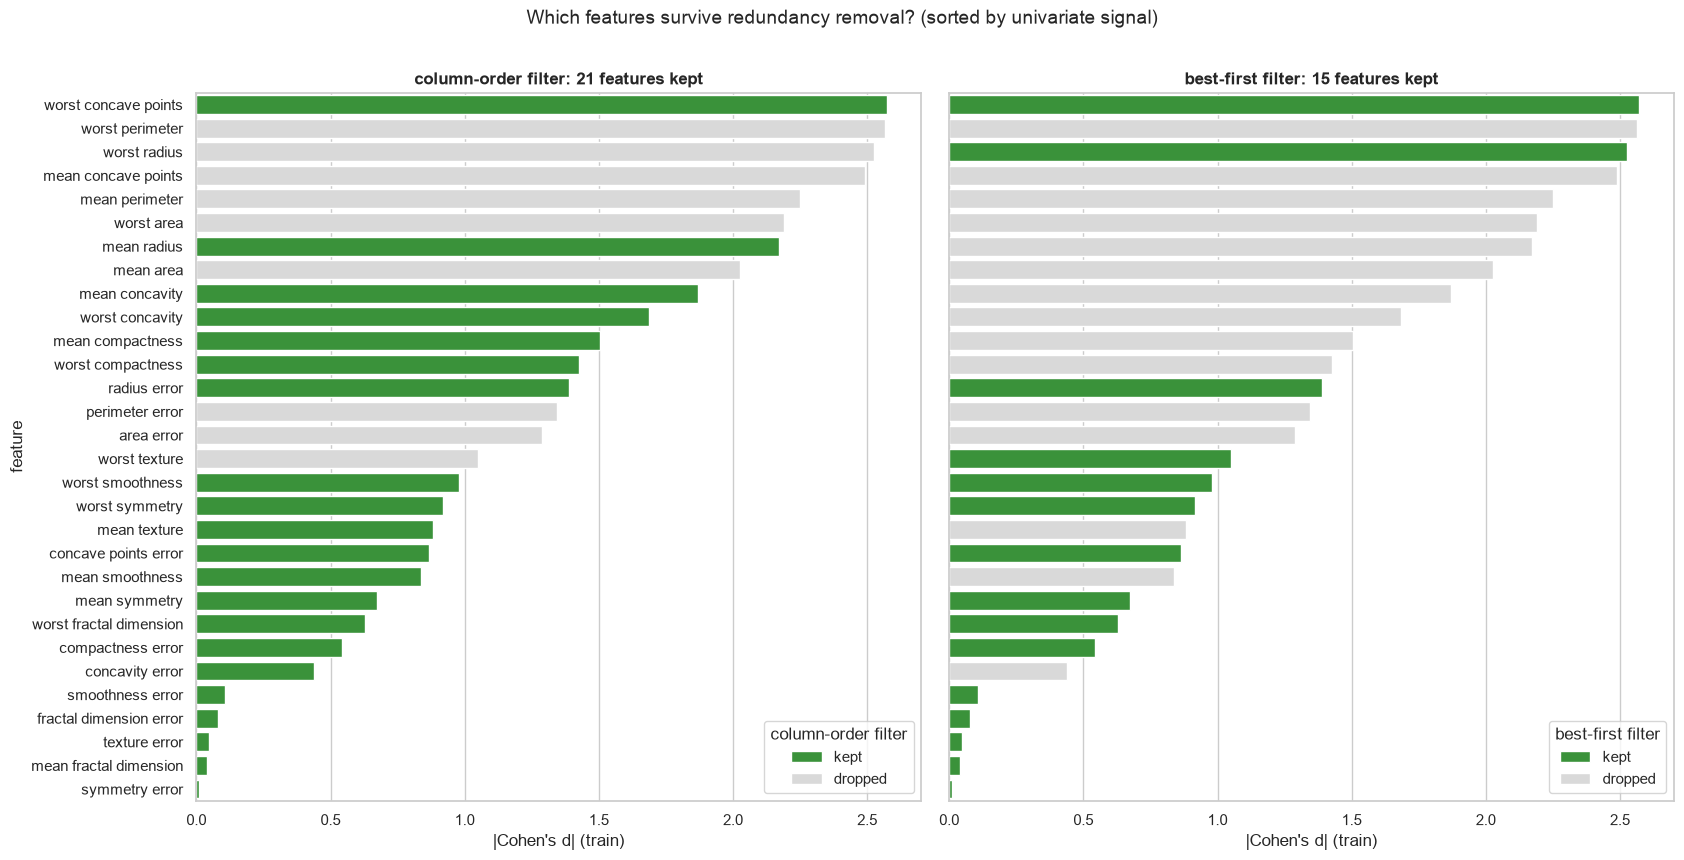

In [26]:
sel_df = pd.DataFrame({"feature": d_train.index, "|Cohen's d| (train)": d_train.values})
sel_df["column-order filter"] = np.where(sel_df["feature"].isin(decor_naive), "kept", "dropped")
sel_df["best-first filter"] = np.where(sel_df["feature"].isin(decor_best), "kept", "dropped")

fig, axes = plt.subplots(1, 2, figsize=(17, 8.5), sharey=True)
for ax, col in zip(axes, ["column-order filter", "best-first filter"]):
    sns.barplot(data=sel_df, y="feature", x="|Cohen's d| (train)", hue=col, dodge=False,
                palette={"kept": "#2ca02c", "dropped": "#d9d9d9"}, ax=ax)
    ax.set_title(f"{col}: {(sel_df[col] == 'kept').sum()} features kept", fontweight="bold")
plt.suptitle("Which features survive redundancy removal? (sorted by univariate signal)",
             y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

The column-order filter throws away `worst perimeter`, `worst radius`, `worst area` and `mean concave points`, which are among the strongest predictors in the dataset, simply because a weaker cousin appeared earlier in the column list. The best-first filter keeps one strong representative of each group (e.g., `worst concave points`, `worst radius`) and is more aggressive (|r| ≤ 0.8), so it also thins out the correlated compactness/concavity cluster.

In [27]:
nb_models = {
    "GNB · 3 concept features":       (make_pipeline(StandardScaler(), GaussianNB()), focus),
    "GNB · 10 mean features":         (make_pipeline(StandardScaler(), GaussianNB()), mean_feats),
    "GNB · all 30":                   (make_pipeline(StandardScaler(), GaussianNB()), feature_names),
    "GNB · all 30 + Yeo–Johnson":     (make_pipeline(PowerTransformer(), GaussianNB()), feature_names),
    "GNB · decorrelated (column order)":   (make_pipeline(StandardScaler(), GaussianNB()), decor_naive),
    "GNB · decorrelated (best-first)":     (make_pipeline(StandardScaler(), GaussianNB()), decor_best),
    "GNB · decorrelated (best-first) + YJ": (make_pipeline(PowerTransformer(), GaussianNB()), decor_best),
    "BernoulliNB · binarized":        (make_pipeline(StandardScaler(), BernoulliNB(binarize=0.0)), feature_names),
    "MultinomialNB · min–max":        (make_pipeline(MinMaxScaler(), MultinomialNB()), feature_names),
}
nb_results = cv_compare(nb_models, X_train, y_train)
summarize(nb_results)

metric,accuracy,recall (malignant),precision (malignant),ROC AUC,log loss,Brier score
model,,,,,,
GNB · 3 concept features,0.922 ± 0.029,0.833 ± 0.065,0.952 ± 0.039,0.977 ± 0.014,0.197 ± 0.042,0.058 ± 0.016
GNB · 10 mean features,0.915 ± 0.025,0.874 ± 0.060,0.898 ± 0.041,0.971 ± 0.016,0.553 ± 0.286,0.074 ± 0.023
GNB · all 30,0.940 ± 0.023,0.899 ± 0.050,0.939 ± 0.038,0.986 ± 0.011,0.621 ± 0.358,0.057 ± 0.021
GNB · all 30 + Yeo–Johnson,0.939 ± 0.020,0.907 ± 0.046,0.931 ± 0.034,0.983 ± 0.010,0.698 ± 0.310,0.058 ± 0.018
GNB · decorrelated (column order),0.914 ± 0.024,0.875 ± 0.053,0.895 ± 0.043,0.961 ± 0.018,0.751 ± 0.362,0.080 ± 0.022
GNB · decorrelated (best-first),0.939 ± 0.026,0.896 ± 0.052,0.940 ± 0.043,0.981 ± 0.015,0.270 ± 0.216,0.050 ± 0.022
GNB · decorrelated (best-first) + YJ,0.925 ± 0.023,0.883 ± 0.056,0.914 ± 0.032,0.981 ± 0.010,0.238 ± 0.101,0.057 ± 0.019
BernoulliNB · binarized,0.932 ± 0.022,0.919 ± 0.051,0.903 ± 0.044,0.981 ± 0.011,0.561 ± 0.235,0.061 ± 0.018
MultinomialNB · min–max,0.837 ± 0.031,0.574 ± 0.081,0.981 ± 0.029,0.924 ± 0.024,0.472 ± 0.019,0.148 ± 0.009


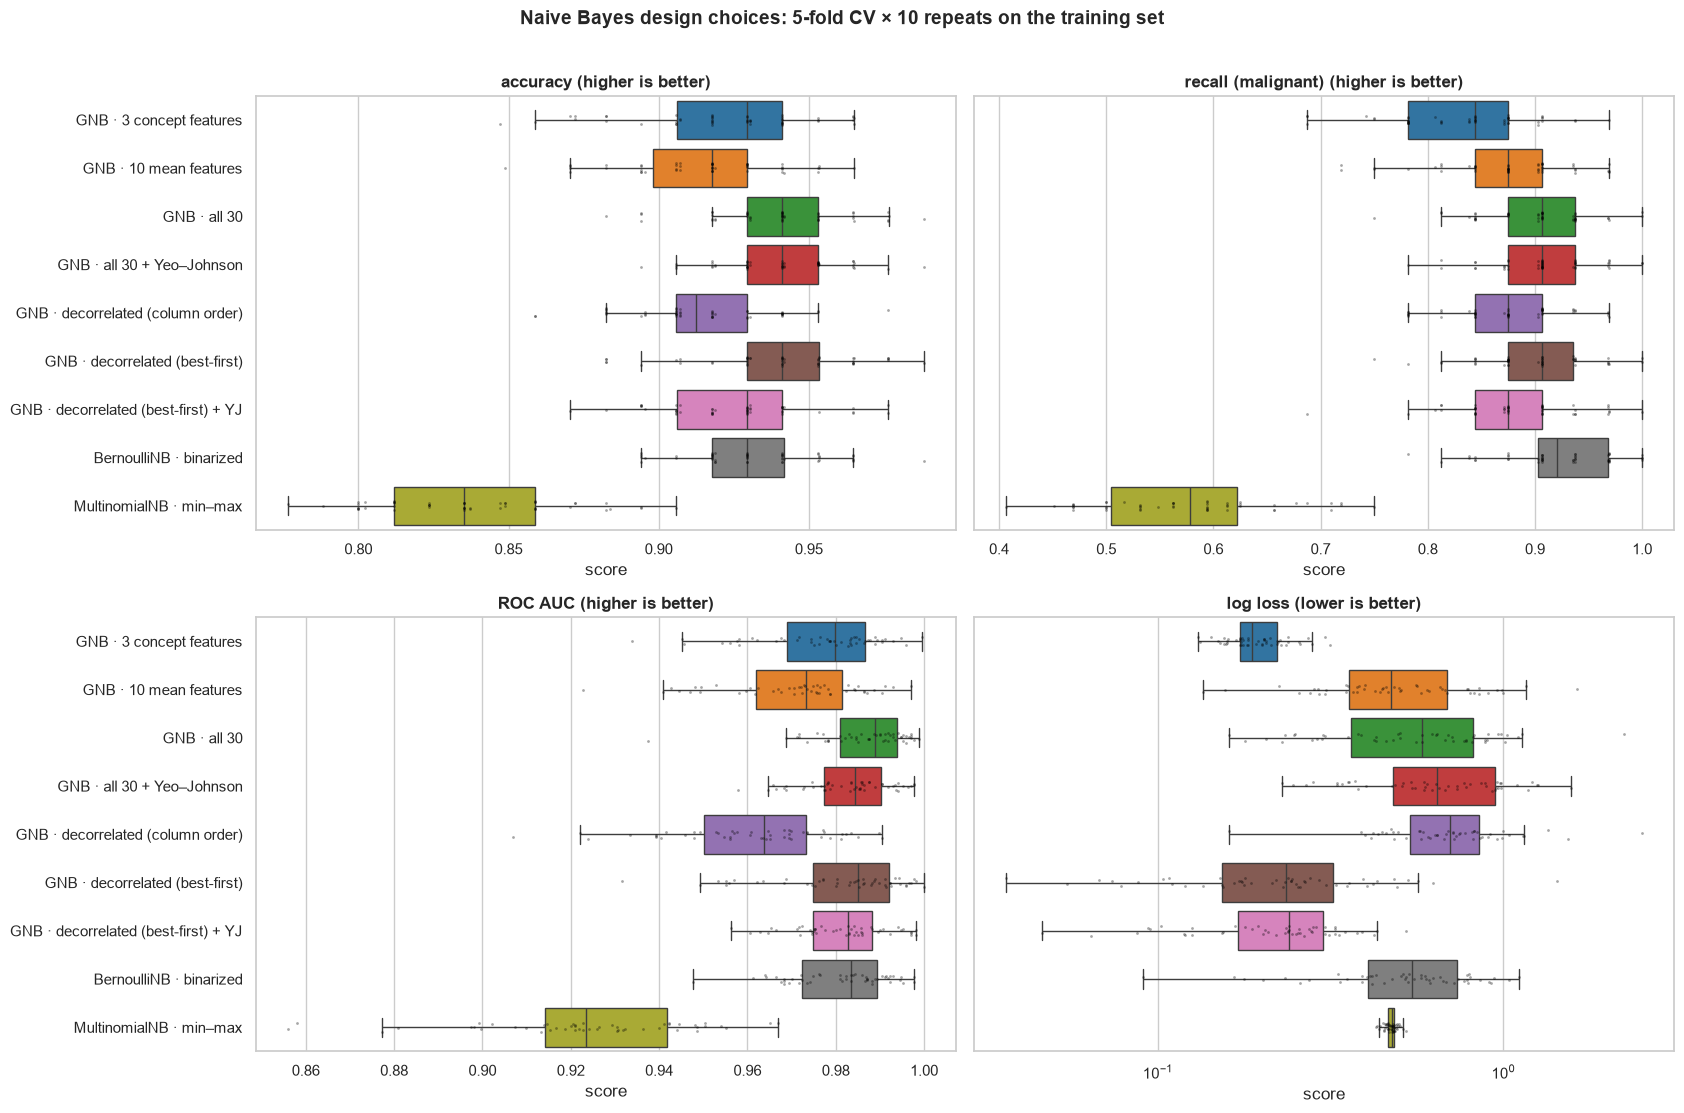

In [28]:
plot_metrics = ["accuracy", "recall (malignant)", "ROC AUC", "log loss"]
order = list(nb_models)
model_colors = dict(zip(order, sns.color_palette("tab10", len(order))))

fig, axes = plt.subplots(2, 2, figsize=(17, 11))
for ax, metric in zip(axes.ravel(), plot_metrics):
    sub = nb_results[nb_results["metric"] == metric]
    sns.boxplot(data=sub, y="model", x="score", order=order, hue="model", palette=model_colors,
                legend=False, showfliers=False, ax=ax)
    sns.stripplot(data=sub, y="model", x="score", order=order, color="black", size=2, alpha=0.35, ax=ax)
    ax.set_title(f"{metric} ({'lower' if metric in LOWER_IS_BETTER else 'higher'} is better)",
                 fontweight="bold")
    ax.set_ylabel("")
    if metric == "log loss":
        ax.set_xscale("log")
for ax in axes[:, 1]:
    ax.set_yticklabels([])
plt.suptitle("Naive Bayes design choices: 5-fold CV × 10 repeats on the training set", y=1.01,
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

**Reading the results.** The numbers come from the summary table above; the plots show the fold-to-fold spread.

1. **The wrong variants behave very differently.** `MultinomialNB` is clearly the worst model (accuracy ≈ 0.84 and it misses over 40% of cancers): measurements are not counts. `BernoulliNB` is surprisingly competitive (accuracy ≈ 0.93, AUC ≈ 0.98). The classes are so well separated that even "above or below the average radius" carries most of the signal. It still loses to `GaussianNB` on accuracy, precision and Brier score, so binarizing throws away information for no benefit. Q1 is confirmed empirically, but "wrong variant" does not always mean "catastrophic".
2. **The three concept features alone are respectable but miss too many cancers.** Accuracy ≈ 0.92, but recall ≈ 0.83: roughly one malignant tumor in six would be missed. Interestingly, this model has the **best log loss**. With only three nearly independent features there is little double counting, so its probabilities are the least overconfident.
3. **Fixing the skew did not help.** Yeo–Johnson barely changes accuracy and AUC and slightly *worsens* log loss with all 30 features. This contradicts the intuition from Part 6 and is an important lesson: the cell below confirms that the transform did dramatically reduce within-class skewness, so the Gaussian shapes really are better. They simply were not the bottleneck. The decision depends on the sign of the summed evidence, and the dominant error in that sum here comes from **double counting correlated features**, not from imperfect bell curves. Fixing an assumption that isn't the binding constraint buys little.
4. **How you remove redundancy matters enormously.** The column-order filter is the second-worst Gaussian model (AUC ≈ 0.96) because it discarded the strongest predictors. The best-first filter matches the all-30 model's accuracy (≈ 0.94) with only 15 features, while cutting log loss by more than half and giving the **best Brier score** of all. That is exactly what removing double counting should do: roughly the same decisions, far less overconfidence.
5. **Log loss is the most revealing metric here.** On its log-scale axis, the all-30 models occasionally assign near-zero probability to the true class, which log loss punishes severely. That is double counting made visible.

**Selecting a configuration.** The top configurations' ROC AUCs (0.98–0.986) differ by less than one standard deviation across folds, so AUC can't separate them. We select by **Brier score**, which rewards both correct ranking *and* honest probabilities, the two things a diagnostic aid needs.

In [29]:
# Evidence for point 3: Yeo–Johnson really did fix the within-class skew (training data only)
pt_check = PowerTransformer().fit(X_train)
Z_train = pd.DataFrame(pt_check.transform(X_train), columns=feature_names, index=X_train.index)
skew_check = pd.DataFrame({
    (version, label): [stats.skew(frame.loc[y_train == k, f]) for f in feature_names]
    for version, frame in [("raw", X_train), ("Yeo–Johnson", Z_train)]
    for label, k in [("benign", 0), ("malignant", 1)]}, index=feature_names)
print("Mean |within-class skewness| across 30 features:")
display(skew_check.abs().mean().round(2).unstack())
skew_check.loc[["mean area", "area error", "mean concavity", "radius error", "worst area"]].round(2)

Mean |within-class skewness| across 30 features:


,benign,malignant
Yeo–Johnson,0.36,0.28
raw,1.34,1.38


raw           Yeo–Johnson          
               benign malignant      benign malignant
mean area        0.38      1.23       -0.79     -0.24
area error       1.69      4.18       -0.46     -0.49
mean concavity   3.64      0.96        0.78     -0.75
radius error     1.60      2.52        0.17     -0.47
worst area       0.42      1.37       -0.77     -0.26

In [30]:
gnb_only = nb_results[nb_results["model"].str.startswith("GNB")]
ranking = (gnb_only.pivot_table(index="model", columns="metric", values="score", aggfunc="mean")
           [list(scoring)].sort_values("Brier score"))
display(ranking.round(4))

best_name = ranking.index[0]
best_est, best_feats = nb_models[best_name]
print(f"Selected configuration: {best_name}  ({len(best_feats)} features)")

metric,accuracy,recall (malignant),precision (malignant),ROC AUC,log loss,Brier score
model,,,,,,
GNB · decorrelated (best-first),0.9392,0.8959,0.9404,0.9807,0.2701,0.0499
GNB · decorrelated (best-first) + YJ,0.9246,0.8832,0.9135,0.9813,0.2385,0.0567
GNB · all 30,0.9399,0.8989,0.9394,0.9861,0.6207,0.0572
GNB · all 30 + Yeo–Johnson,0.9394,0.9070,0.9306,0.9826,0.6975,0.0580
GNB · 3 concept features,0.9216,0.8334,0.9515,0.9767,0.1973,0.0585
GNB · 10 mean features,0.9150,0.8738,0.8983,0.9705,0.5534,0.0741
GNB · decorrelated (column order),0.9139,0.8745,0.8950,0.9607,0.7506,0.0796


Selected configuration: GNB · decorrelated (best-first)  (15 features)


## Part 10 (Q6): Can we trust the probabilities? Calibration

In medicine, *"78% probability of malignancy"* should mean that among many such patients about 78% actually have cancer. That property is called **calibration**. Part 7 predicted that redundant features would make Naive Bayes overconfident. Let's check, using **out-of-fold** predictions on the training set so every prediction comes from a model that never saw that patient.

In [31]:
oof_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

calib_models = {
    "GNB · all 30 (standardized)":  (make_pipeline(StandardScaler(), GaussianNB()), feature_names),
    f"Selected: {best_name}":       (best_est, best_feats),
    "Selected + isotonic calibration": (CalibratedClassifierCV(best_est, method="isotonic", cv=5), best_feats),
    "Logistic regression (reference)": (make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)), feature_names),
}

oof_probs = {name: cross_val_predict(est, X_train[cols], y_train, cv=oof_cv, method="predict_proba")[:, 1]
             for name, (est, cols) in calib_models.items()}

calib_table = pd.DataFrame({
    name: {"Brier score": brier_score_loss(y_train, p),
           "log loss": log_loss(y_train, np.clip(p, 1e-15, 1 - 1e-15)),
           "ROC AUC": roc_auc_score(y_train, p),
           "% predictions < 1% or > 99%": np.mean((p < 0.01) | (p > 0.99)) * 100,
           "patients told P < 1%": int((p < 0.01).sum()),
           "...of whom had cancer": int(((p < 0.01) & (y_train == 1)).sum()),
           "observed cancer rate in that group (%)": y_train[p < 0.01].mean() * 100}
    for name, p in oof_probs.items()}).T
calib_table

,Brier score,log loss,ROC AUC,% predictions < 1% or > 99%,patients told P < 1%,...of whom had cancer,observed cancer rate in that group (%)
GNB · all 30 (standardized),0.0581,0.5885,0.9870,96.2441,263.0,13.0,4.9430
Selected: GNB · decorrelated (best-first),0.0539,0.2887,0.9788,85.4460,235.0,6.0,2.5532
Selected + isotonic calibration,0.0451,0.2229,0.9808,61.2676,184.0,1.0,0.5435
Logistic regression (reference),0.0217,0.0903,0.9914,68.0751,177.0,2.0,1.1299


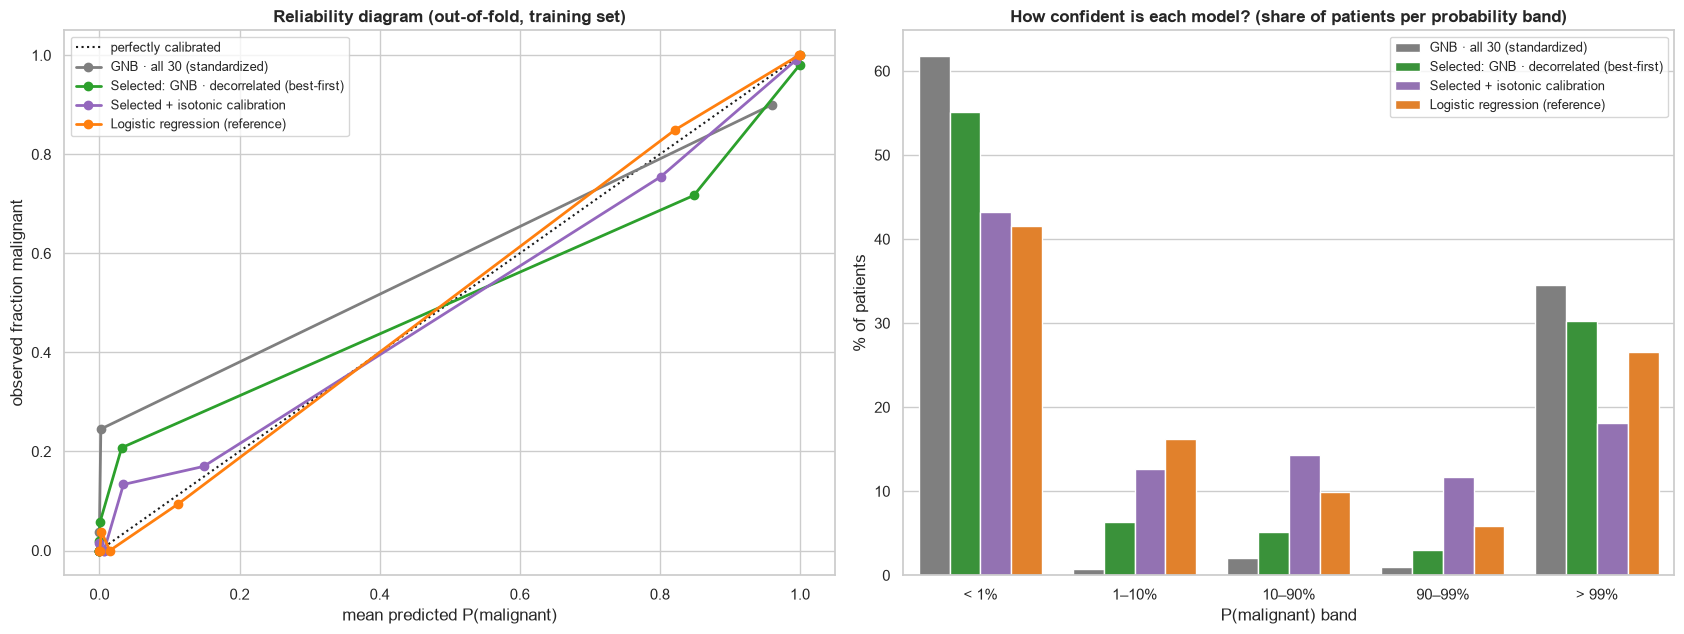

In [32]:
calib_colors = dict(zip(calib_models, ["#7f7f7f", "#2ca02c", "#9467bd", "#ff7f0e"]))

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
ax = axes[0]
ax.plot([0, 1], [0, 1], "k:", label="perfectly calibrated")
for name, p in oof_probs.items():
    frac_pos, mean_pred = calibration_curve(y_train, p, n_bins=8, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", lw=2, color=calib_colors[name], label=name)
ax.set_xlabel("mean predicted P(malignant)")
ax.set_ylabel("observed fraction malignant")
ax.set_title("Reliability diagram (out-of-fold, training set)", fontweight="bold")
ax.legend(fontsize=9)

band_labels = ["< 1%", "1–10%", "10–90%", "90–99%", "> 99%"]
band_rows = []
for name, p in oof_probs.items():
    b = pd.cut(p, bins=[-1e-9, 0.01, 0.1, 0.9, 0.99, 1.0 + 1e-9], labels=band_labels)
    for lab, share in (pd.Series(b).value_counts(normalize=True) * 100).items():
        band_rows.append({"model": name, "P(malignant) band": lab, "% of patients": share})
band_df = pd.DataFrame(band_rows)
sns.barplot(data=band_df, x="P(malignant) band", y="% of patients", hue="model", order=band_labels,
            palette=calib_colors, ax=axes[1])
axes[1].set_title("How confident is each model? (share of patients per probability band)",
                  fontweight="bold")
axes[1].legend(fontsize=9)
plt.tight_layout()
plt.show()

What to look for:

- **The all-30 model is certain about almost everyone.** Over 95% of its predictions are below 1% or above 99%. The table makes the danger concrete: among the patients it assigns less than 1% risk, about 5% actually have cancer, a dozen tumors in the training set alone. A model that says "under 1%" should be wrong less than 1% of the time. In the reliability diagram this shows up as the grey curve lying well *above* the diagonal at the low end. That is the double counting from Part 7 turned into false certainty.
- **The selected (decorrelated) model is less extreme** and better calibrated (lower Brier score and log loss), though it is still overconfident.
- **Isotonic calibration** (`CalibratedClassifierCV`) learns a monotone mapping from NB's scores to honest probabilities using internal cross-validation. Because the mapping is monotone it **preserves the ranking** (ROC AUC stays essentially the same) while fixing the probability *values*: the Brier score drops, the curve moves onto the diagonal, and among patients now told "under 1%" the observed cancer rate is roughly in line with that promise.
- **Logistic regression is still better calibrated** than even the calibrated NB. It fits its probabilities directly rather than assembling them from independent pieces.

**Q6 verdict (calibration) / (interpretability):** raw NB probabilities should not be reported to a clinician as-is, but they are easily repaired with calibration. Interpretability is excellent (Part 13).


## Part 11 (Q5, Q7): How does Naive Bayes compare to alternatives?

A model is only "a good choice" relative to what else we could use. We compare against:

- **Logistic regression**: also linear-ish and interpretable, but *learns* weights jointly, so it handles correlated features without double counting.
- **LDA**: Gaussian classes with a *shared* full covariance matrix (models correlations; linear boundary).
- **QDA**: Gaussian classes with *separate* full covariance matrices. This is GaussianNB **without** the naive assumption, so comparing the two isolates the cost of the independence assumption.
- **k-nearest neighbours** and **random forest**: flexible, assumption-light references.

In [35]:
cv_fast = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE)

zoo = {
    f"Gaussian NB ({best_name.replace('GNB · ', '')})": (best_est, best_feats),
    "Gaussian NB + isotonic":  (CalibratedClassifierCV(best_est, method="isotonic", cv=5), best_feats),
    "Logistic regression":     (make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)), feature_names),
    "LDA":                     (make_pipeline(StandardScaler(), LinearDiscriminantAnalysis()), feature_names),
    "QDA (reg=0.1)":           (make_pipeline(StandardScaler(), QuadraticDiscriminantAnalysis(reg_param=0.1)), feature_names),
    "k-NN (k=7)":              (make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7)), feature_names),
    "Random forest":           (RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1), feature_names),
}
zoo_results = cv_compare(zoo, X_train, y_train, cv=cv_fast)
summarize(zoo_results)

metric,accuracy,recall (malignant),precision (malignant),ROC AUC,log loss,Brier score
model,,,,,,
Gaussian NB (decorrelated (best-first)),0.941 ± 0.022,0.896 ± 0.043,0.946 ± 0.039,0.981 ± 0.015,0.255 ± 0.155,0.048 ± 0.019
Gaussian NB + isotonic,0.943 ± 0.020,0.902 ± 0.038,0.946 ± 0.044,0.983 ± 0.012,0.237 ± 0.218,0.042 ± 0.015
Logistic regression,0.973 ± 0.023,0.947 ± 0.048,0.980 ± 0.025,0.993 ± 0.009,0.089 ± 0.054,0.022 ± 0.013
LDA,0.953 ± 0.024,0.884 ± 0.060,0.989 ± 0.019,0.991 ± 0.008,0.147 ± 0.076,0.038 ± 0.019
QDA (reg=0.1),0.969 ± 0.013,0.936 ± 0.038,0.982 ± 0.020,0.992 ± 0.011,0.145 ± 0.125,0.027 ± 0.012
k-NN (k=7),0.961 ± 0.019,0.906 ± 0.047,0.988 ± 0.019,0.986 ± 0.012,0.307 ± 0.291,0.032 ± 0.010
Random forest,0.955 ± 0.021,0.928 ± 0.041,0.952 ± 0.036,0.988 ± 0.012,0.172 ± 0.178,0.034 ± 0.009


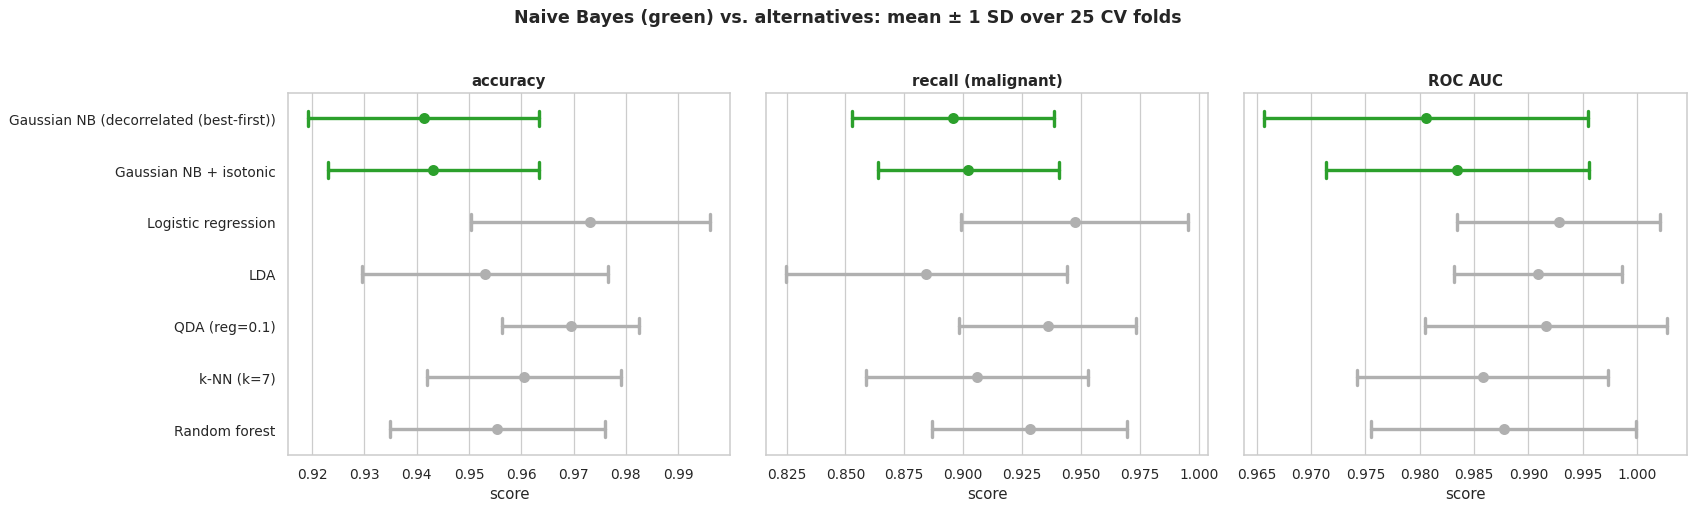

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
zoo_order = list(zoo)
zoo_colors = {m: ("#2ca02c" if m.startswith("Gaussian NB") else "#b0b0b0") for m in zoo_order}
for ax, metric in zip(axes, ["accuracy", "recall (malignant)", "ROC AUC"]):
    sub = zoo_results[zoo_results["metric"] == metric]
    sns.pointplot(data=sub, y="model", x="score", order=zoo_order, hue="model", palette=zoo_colors,
                  errorbar="sd", capsize=0.3, linestyle="none", legend=False, ax=ax)
    ax.set_title(metric, fontweight="bold")
    ax.set_ylabel("")
for ax in axes[1:]:
    ax.set_yticklabels([])
plt.suptitle("Naive Bayes (green) vs. alternatives: mean ± 1 SD over 25 CV folds",
             y=1.03, fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

### Learning curves (Q5): how much data does each model need?

Naive Bayes has very few parameters and no optimization, so it typically reaches its plateau with very little data. A discriminative model like logistic regression often overtakes it once there is enough data. This is the classic generative-vs-discriminative trade-off described by Ng & Jordan (2002).

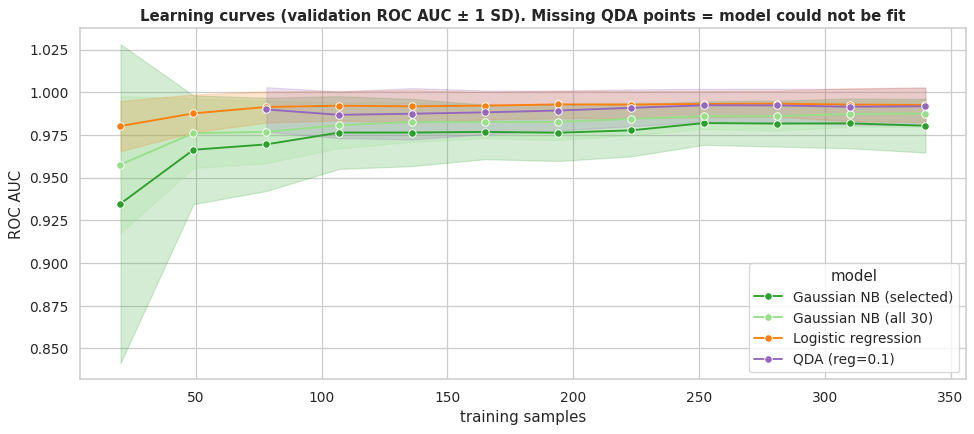

In [37]:
lc_models = {
    "Gaussian NB (selected)": (best_est, best_feats),
    "Gaussian NB (all 30)": (make_pipeline(StandardScaler(), GaussianNB()), feature_names),
    "Logistic regression": (make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)), feature_names),
    "QDA (reg=0.1)": (make_pipeline(StandardScaler(), QuadraticDiscriminantAnalysis(reg_param=0.1)), feature_names),
}
lc_rows = []
for name, (est, cols) in lc_models.items():
    sizes, _, test_scores = learning_curve(
        est, X_train[cols], y_train, train_sizes=np.linspace(0.06, 1.0, 12), shuffle=True,
        cv=RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=RANDOM_STATE),
        scoring="roc_auc", random_state=RANDOM_STATE)
    for s, row in zip(sizes, test_scores):
        lc_rows += [{"model": name, "training samples": s, "ROC AUC": v} for v in row]
lc = pd.DataFrame(lc_rows)

fig, ax = plt.subplots(figsize=(11, 5))
sns.lineplot(data=lc, x="training samples", y="ROC AUC", hue="model", marker="o", errorbar="sd",
             palette={"Gaussian NB (selected)": "#2ca02c", "Gaussian NB (all 30)": "#98df8a",
                      "Logistic regression": "#ff7f0e", "QDA (reg=0.1)": "#9467bd"}, ax=ax)
ax.set_title("Learning curves (validation ROC AUC ± 1 SD). Missing QDA points = model could not be fit",
             fontweight="bold")
plt.tight_layout()
plt.show()

**What the comparison shows**

- **Naive Bayes is competitive but clearly not the top performer.** It reaches ≈ 94% accuracy and ≈ 0.98 AUC, which would have been an excellent result in the 1990s, but logistic regression (≈ 97%, AUC ≈ 0.99) and regularized QDA (≈ 97%) are better on every metric, including the clinically crucial recall.
- **The GNB-vs-QDA gap measures the price of the naive assumption.** Both assume Gaussian classes with class-specific spreads; the only difference is that QDA models correlations. QDA's ≈ 3-point accuracy gain says the independence violation found in Part 7 *does* cost us here.
- **The learning curves show why the naive assumption exists.** QDA cannot even be fitted with small training sets: it needs a full covariance matrix per class ($30 \times 31 / 2 = 465$ numbers each), which is impossible to estimate when a class has fewer samples than features. Naive Bayes needs only 60 numbers per class and works from a few dozen samples, plateauing by about 100.
- **But the classic "NB wins on small data" story does not hold here.** Ng & Jordan's (2002) result predicts that NB can beat logistic regression when training data is scarce. On this dataset, L2-regularized logistic regression is better at *every* training size: regularization gives it the same stability NB gets from its assumptions, without the double counting.

**Q5 verdict  :** NB is data-efficient and stable, but so is regularized logistic regression, which is better here at every sample size.  
**Q7 verdict  :** a strong, sensible baseline, not the best final model for this dataset.

---
## Part 12: Clinical decision threshold and final test evaluation

### 12.1 Choosing the threshold

By default a classifier predicts "malignant" when $P(\text{malignant}) > 0.5$. But the two errors have very different costs:

- **False negative** (cancer predicted benign): delayed treatment, potentially fatal.
- **False positive** (benign predicted cancer): anxiety and a follow-up biopsy.

A screening-style tool should prioritize **recall (sensitivity) for malignant tumors**. We choose the threshold on out-of-fold *training* predictions, aiming for ≥ 97% sensitivity, and only then look at the test set. We use the calibrated model so that the threshold corresponds to a meaningful probability.

Out-of-fold operating points on the training set (159 malignant, 267 benign):


,target sensitivity,threshold,sensitivity,specificity,missed cancers,false alarms
0,≥ 85%,0.806,0.8553,0.9963,23,1
1,≥ 90%,0.541,0.9057,0.9588,15,11
2,≥ 95%,0.145,0.9560,0.8951,7,28
3,≥ 97%,0.055,0.9748,0.7753,4,60
4,≥ 99%,0.036,0.9937,0.7228,1,74


Highest threshold reaching ≥97% out-of-fold sensitivity: 0.055


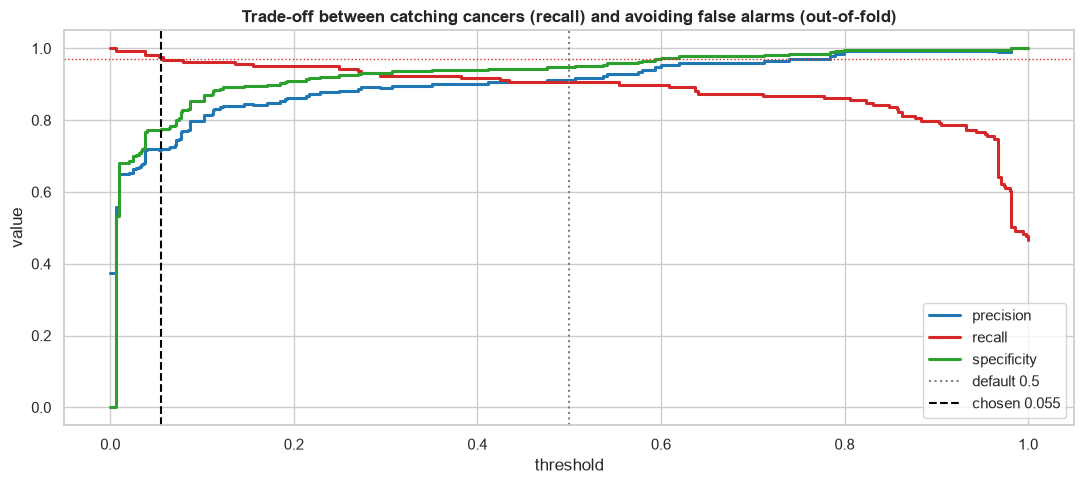

In [33]:
final_model = CalibratedClassifierCV(best_est, method="isotonic", cv=5)
oof_final = cross_val_predict(final_model, X_train[best_feats], y_train, cv=oof_cv, method="predict_proba")[:, 1]

prec, rec, thr = precision_recall_curve(y_train, oof_final)
thr_df = pd.DataFrame({"threshold": thr, "precision": prec[:-1], "recall": rec[:-1]})
thr_df["specificity"] = [((oof_final < t) & (y_train == 0)).sum() / (y_train == 0).sum() for t in thr]

def oof_operating_point(target):
    t = float(thr_df.loc[thr_df["recall"] >= target, "threshold"].max())
    pred = (oof_final >= t).astype(int)
    return {"target sensitivity": f"≥ {target:.0%}", "threshold": round(t, 3),
            "sensitivity": recall_score(y_train, pred),
            "specificity": ((pred == 0) & (y_train == 0)).sum() / (y_train == 0).sum(),
            "missed cancers": int(((pred == 0) & (y_train == 1)).sum()),
            "false alarms": int(((pred == 1) & (y_train == 0)).sum())}

print(f"Out-of-fold operating points on the training set ({y_train.sum()} malignant, {(y_train == 0).sum()} benign):")
display(pd.DataFrame([oof_operating_point(t) for t in (0.85, 0.90, 0.95, 0.97, 0.99)]))

TARGET_RECALL = 0.97
eligible = thr_df[thr_df["recall"] >= TARGET_RECALL]
chosen_threshold = float(eligible["threshold"].max())
print(f"Highest threshold reaching ≥{TARGET_RECALL:.0%} out-of-fold sensitivity: {chosen_threshold:.3f}")

long_thr = thr_df.melt(id_vars="threshold", value_vars=["precision", "recall", "specificity"],
                       var_name="metric", value_name="value")
fig, ax = plt.subplots(figsize=(11, 5))
sns.lineplot(data=long_thr, x="threshold", y="value", hue="metric", lw=2.2, drawstyle="steps-post",
             palette={"precision": "#1f77b4", "recall": "#d62728", "specificity": "#2ca02c"}, ax=ax)
ax.axvline(0.5, color="gray", ls=":", label="default 0.5")
ax.axvline(chosen_threshold, color="black", ls="--", label=f"chosen {chosen_threshold:.3f}")
ax.axhline(TARGET_RECALL, color="#d62728", ls=":", lw=1)
ax.set_title("Trade-off between catching cancers (recall) and avoiding false alarms (out-of-fold)",
             fontweight="bold")
ax.legend()
plt.tight_layout()
plt.show()

### 12.2 Final evaluation on the untouched test set

The table makes the trade-off concrete: each step up in sensitivity costs additional false alarms, and the last few percent are the most expensive. We pick the **97%** operating point, a typical choice for a tool meant to flag tumors for further work-up rather than to make the final diagnosis. Notice how *low* the resulting threshold is: any tumor with a calibrated malignancy probability of just a few percent gets flagged. Because the probabilities are calibrated, that threshold has a direct meaning ("flag if the estimated risk is at least about 1 in 20"). With uncalibrated NB probabilities it would be an arbitrary number.

### 12.2 Final evaluation on the untouched test set

We now refit the chosen model on the full training set and evaluate it **once** on the 143 held-out tumors, at both the default and the clinically chosen threshold.

In [34]:
final_model.fit(X_train[best_feats], y_train)
p_test = final_model.predict_proba(X_test[best_feats])[:, 1]

def report_at(threshold):
    pred = (p_test >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return {"threshold": round(threshold, 3),
            "accuracy": accuracy_score(y_test, pred),
            "sensitivity (recall M)": tp / (tp + fn),
            "specificity": tn / (tn + fp),
            "precision (PPV)": precision_score(y_test, pred),
            "missed cancers (FN)": fn,
            "false alarms (FP)": fp}

test_summary = pd.DataFrame([report_at(0.5), report_at(chosen_threshold)],
                            index=["default 0.5", "clinical threshold"])
print(f"Test ROC AUC: {roc_auc_score(y_test, p_test):.4f}   |   "
      f"Average precision: {average_precision_score(y_test, p_test):.4f}   |   "
      f"Brier: {brier_score_loss(y_test, p_test):.4f}")
test_summary

Test ROC AUC: 0.9910   |   Average precision: 0.9858   |   Brier: 0.0390


,threshold,accuracy,sensitivity (recall M),specificity,precision (PPV),missed cancers (FN),false alarms (FP)
default 0.5,0.500,0.9301,0.8679,0.9667,0.9388,7,3
clinical threshold,0.055,0.8811,1.0000,0.8111,0.7571,0,17


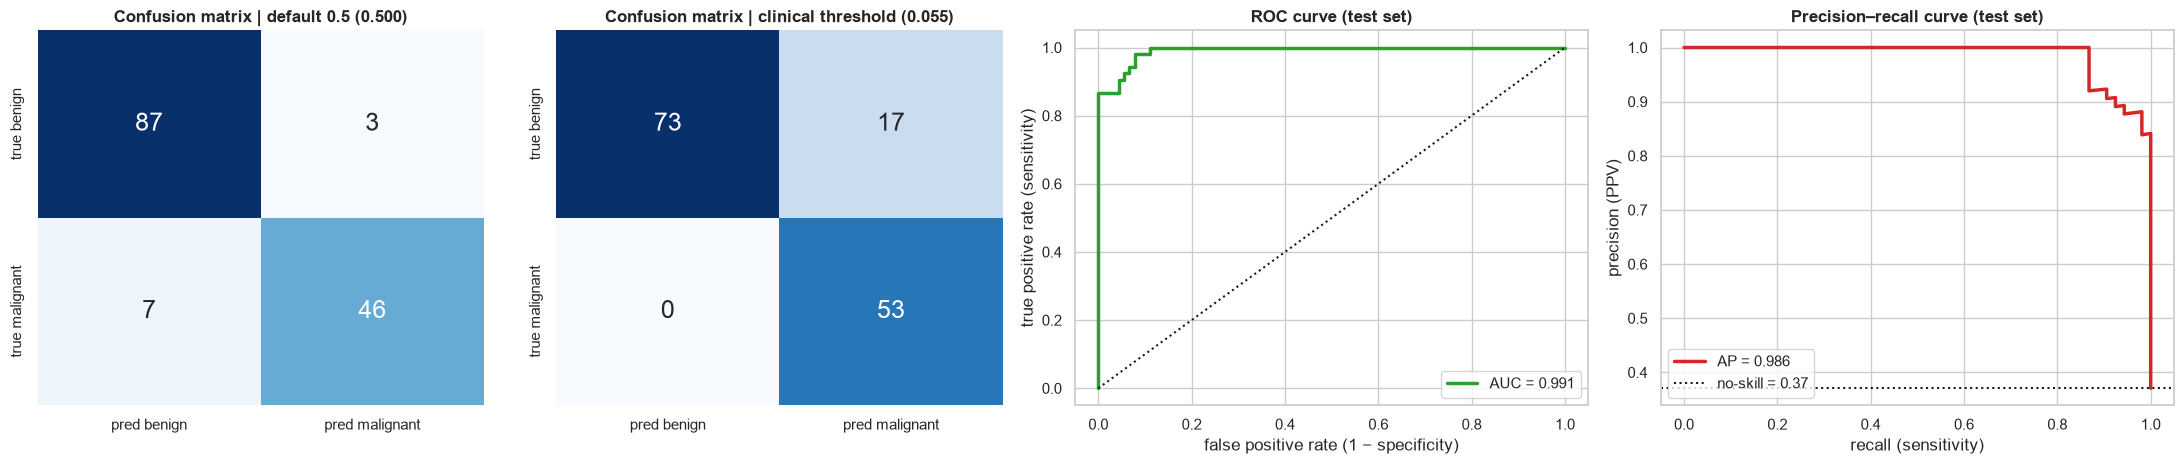

              precision    recall  f1-score   support

      benign      1.000     0.811     0.896        90
   malignant      0.757     1.000     0.862        53

    accuracy                          0.881       143
   macro avg      0.879     0.906     0.879       143
weighted avg      0.910     0.881     0.883       143



In [35]:
fig, axes = plt.subplots(1, 4, figsize=(22, 4.8), gridspec_kw={"width_ratios": [1, 1, 1.15, 1.15]})
for ax, (label, t) in zip(axes[:2], [("default 0.5", 0.5), ("clinical threshold", chosen_threshold)]):
    cm = confusion_matrix(y_test, (p_test >= t).astype(int))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, annot_kws={"size": 18},
                xticklabels=["pred benign", "pred malignant"], yticklabels=["true benign", "true malignant"],
                ax=ax)
    ax.set_title(f"Confusion matrix | {label} ({t:.3f})", fontweight="bold")

fpr, tpr, _ = roc_curve(y_test, p_test)
axes[2].plot(fpr, tpr, color="#2ca02c", lw=2.5, label=f"AUC = {roc_auc_score(y_test, p_test):.3f}")
axes[2].plot([0, 1], [0, 1], "k:")
axes[2].set_xlabel("false positive rate (1 − specificity)")
axes[2].set_ylabel("true positive rate (sensitivity)")
axes[2].set_title("ROC curve (test set)", fontweight="bold")
axes[2].legend(loc="lower right")

pr_p, pr_r, _ = precision_recall_curve(y_test, p_test)
axes[3].plot(pr_r, pr_p, color="#d62728", lw=2.5, label=f"AP = {average_precision_score(y_test, p_test):.3f}")
axes[3].axhline(y_test.mean(), color="k", ls=":", label=f"no-skill = {y_test.mean():.2f}")
axes[3].set_xlabel("recall (sensitivity)")
axes[3].set_ylabel("precision (PPV)")
axes[3].set_title("Precision–recall curve (test set)", fontweight="bold")
axes[3].legend(loc="lower left")
plt.tight_layout()
plt.show()

print(classification_report(y_test, (p_test >= chosen_threshold).astype(int),
                            target_names=["benign", "malignant"], digits=3))

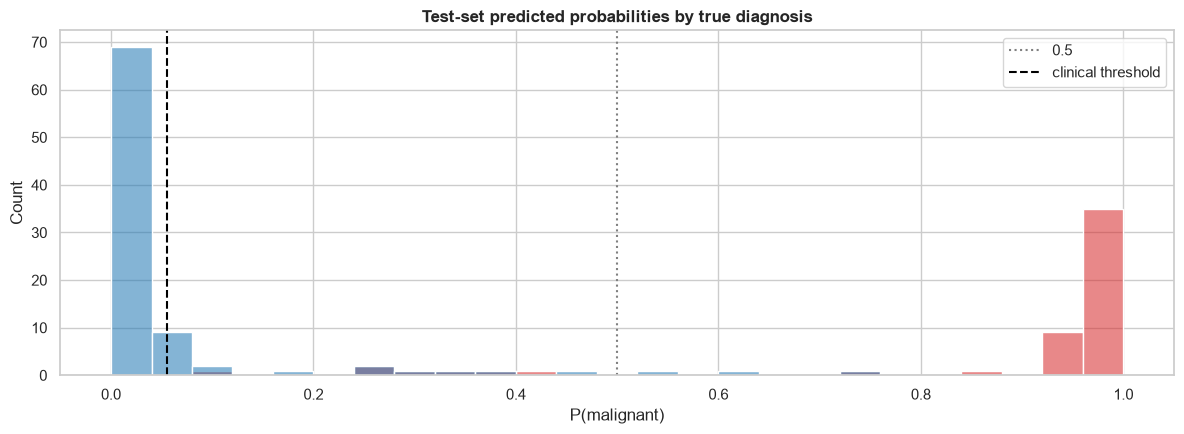

In [36]:
test_frame = pd.DataFrame({"P(malignant)": p_test,
                           "true diagnosis": np.where(y_test == 1, "malignant", "benign")})
fig, ax = plt.subplots(figsize=(12, 4.5))
sns.histplot(data=test_frame, x="P(malignant)", hue="true diagnosis", hue_order=CLASS_ORDER,
             palette=PALETTE, bins=25, multiple="layer", alpha=0.55, ax=ax)
ax.axvline(0.5, color="gray", ls=":", label="0.5")
ax.axvline(chosen_threshold, color="black", ls="--", label="clinical threshold")
ax.set_title("Test-set predicted probabilities by true diagnosis", fontweight="bold")
ax.legend()
plt.tight_layout()
plt.show()

On the test set the clinical threshold behaves as intended: at the default 0.5 the model misses 7 of the 53 cancers, while at the chosen threshold it misses **none**, at the price of 17 false alarms (specificity falls from ≈ 97% to ≈ 81%). Whether that trade is acceptable is a clinical decision, not a statistical one; the point is that it should be made *deliberately*.

Because the threshold was chosen on training data only, these numbers are an honest estimate, with the caveat that 143 samples (53 malignant) is small: each missed cancer moves sensitivity by about 2 percentage points, so "100%" should be read as "very high", not as a guarantee.


## Part 13: Explaining individual predictions

Because the log posterior odds is a **sum** (Part 2), we can decompose any prediction exactly into the prior plus one evidence term per feature:

$$
\underbrace{\log\frac{P(M\mid\mathbf{x})}{P(B\mid\mathbf{x})}}_{\text{total}}
= \log\frac{P(M)}{P(B)} + \sum_i \Big[\log \mathcal{N}(z_i;\mu_{iM},\sigma^2_{iM}) - \log \mathcal{N}(z_i;\mu_{iB},\sigma^2_{iB})\Big]
$$

where $z_i$ is the (transformed) feature value. Positive terms push toward malignant, negative toward benign. We explain the **uncalibrated** NB pipeline, since isotonic calibration is a monotone re-mapping applied on top of these scores and doesn't change which features drove the decision.

In [37]:
explain_model = best_est.fit(X_train[best_feats], y_train)
preprocess, nb = explain_model[:-1], explain_model[-1]

def evidence(row_df):
    z = preprocess.transform(row_df)[0]
    sd = np.sqrt(nb.var_)
    llr = stats.norm.logpdf(z, nb.theta_[1], sd[1]) - stats.norm.logpdf(z, nb.theta_[0], sd[0])
    prior = np.log(nb.class_prior_[1] / nb.class_prior_[0])
    return pd.Series(llr, index=best_feats), prior

# Sanity check: our decomposition reproduces scikit-learn's own log-odds exactly
row = X_test[best_feats].iloc[[0]]
contrib, prior_term = evidence(row)
lp = explain_model.predict_log_proba(row)[0]
print(f"Our log-odds: {prior_term + contrib.sum():.6f}   |   scikit-learn: {lp[1] - lp[0]:.6f}")

Our log-odds: 22.553828   |   scikit-learn: 22.553828


Uncalibrated log-odds on the test set: median for malignant tumors 15.5, maximum 75.1, minimum -32.3


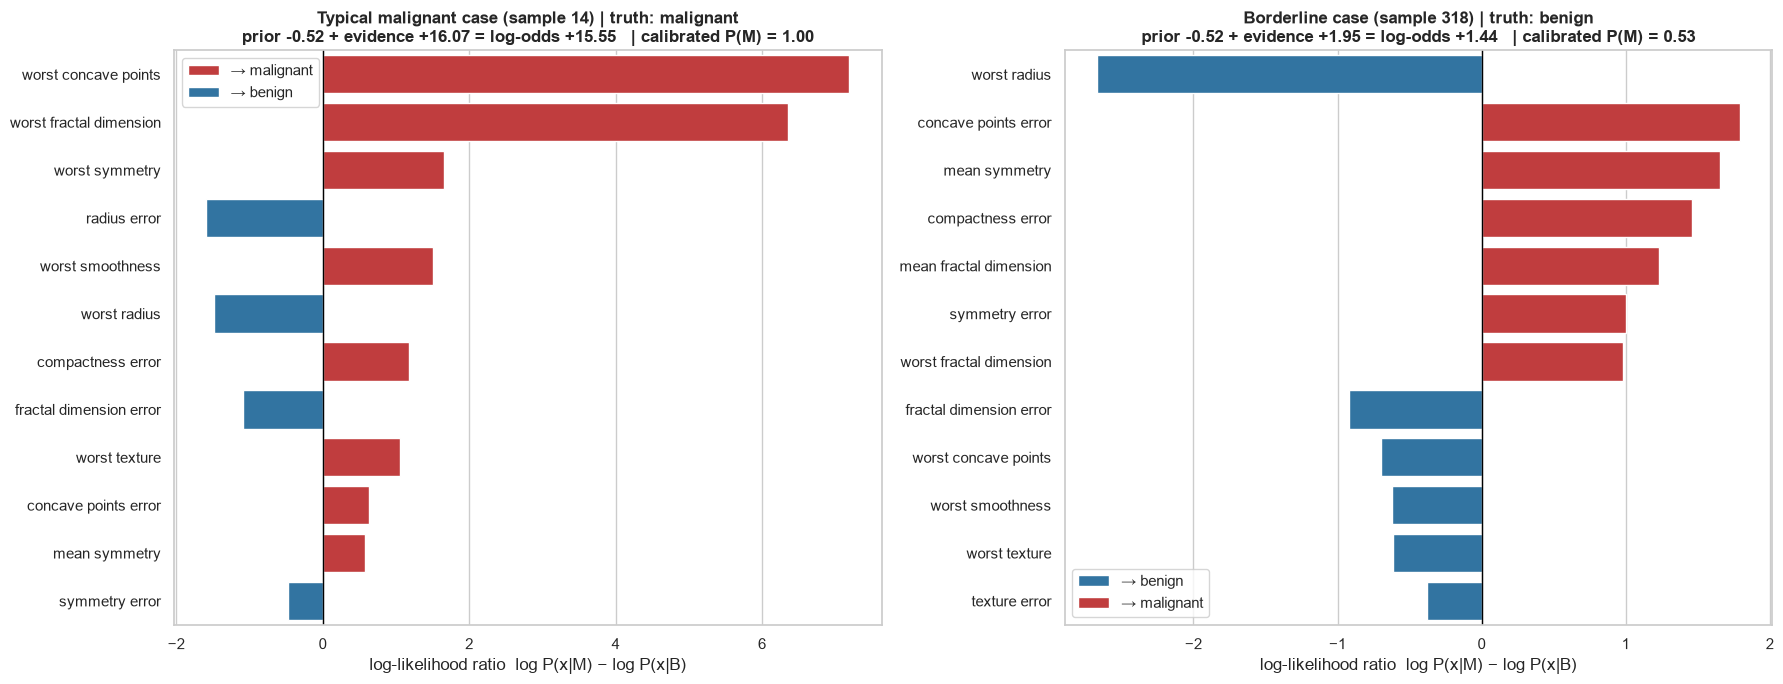

In [38]:
lp_test = explain_model.predict_log_proba(X_test[best_feats])
log_odds_test = pd.Series(lp_test[:, 1] - lp_test[:, 0], index=X_test.index)
malignant_lo = log_odds_test[y_test == 1]
idx_typical = (malignant_lo - malignant_lo.median()).abs().idxmin()   # a typical malignant tumor
idx_borderline = X_test.index[np.argmin(np.abs(p_test - 0.5))]        # the most uncertain case

print("Uncalibrated log-odds on the test set: median for malignant tumors "
      f"{malignant_lo.median():.1f}, maximum {log_odds_test.max():.1f}, minimum {log_odds_test.min():.1f}")

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for ax, idx, title in zip(axes, [idx_typical, idx_borderline], ["Typical malignant case", "Borderline case"]):
    contrib, prior_term = evidence(X_test.loc[[idx], best_feats])
    top = contrib.reindex(contrib.abs().sort_values(ascending=False).index).head(12)
    sns.barplot(x=top.values, y=top.index, hue=np.where(top.values > 0, "→ malignant", "→ benign"),
                palette={"→ malignant": PALETTE["malignant"], "→ benign": PALETTE["benign"]},
                dodge=False, ax=ax)
    ax.axvline(0, color="black", lw=1)
    total = prior_term + contrib.sum()
    truth = "malignant" if y_test.loc[idx] == 1 else "benign"
    ax.set_title(f"{title} (sample {idx}) | truth: {truth}\n"
                 f"prior {prior_term:+.2f} + evidence {contrib.sum():+.2f} = log-odds {total:+.2f}   "
                 f"| calibrated P(M) = {p_test[X_test.index.get_loc(idx)]:.2f}", fontweight="bold")
    ax.set_xlabel("log-likelihood ratio  log P(x|M) − log P(x|B)")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

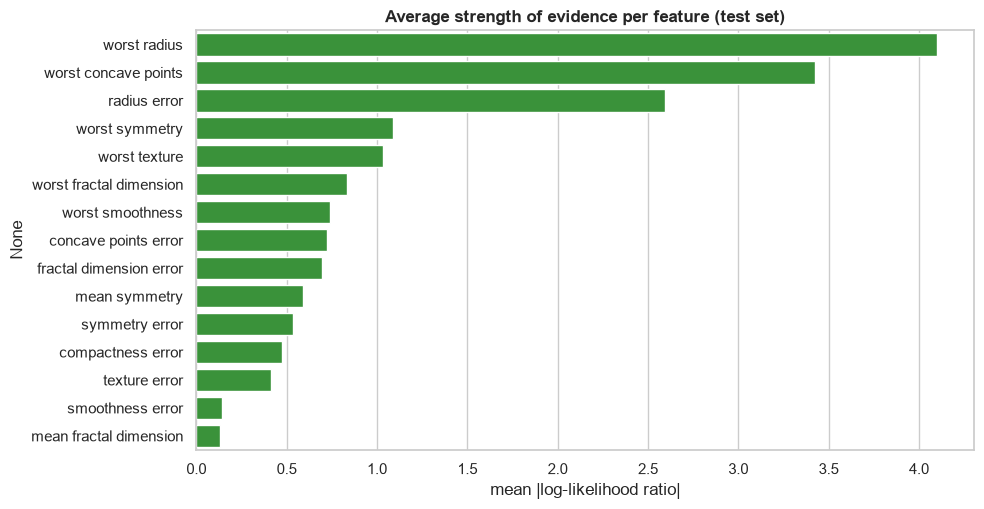

In [39]:
# Global view: which features contribute the most evidence on average across the test set?
all_contrib = pd.DataFrame([evidence(X_test.loc[[i], best_feats])[0] for i in X_test.index])
global_imp = all_contrib.abs().mean().sort_values(ascending=False).rename("mean |log-likelihood ratio|")

fig, ax = plt.subplots(figsize=(10, max(4, 0.35 * len(global_imp))))
sns.barplot(x=global_imp.values, y=global_imp.index, color="#2ca02c", ax=ax)
ax.set_title("Average strength of evidence per feature (test set)", fontweight="bold")
ax.set_xlabel("mean |log-likelihood ratio|")
plt.tight_layout()
plt.show()

This kind of explanation is a genuine strength of Naive Bayes. A clinician can see *exactly* which measurements pushed the model toward malignancy, and by how much, with no approximation. The borderline case shows features pulling in **opposite directions**, which is precisely when human review matters most.

The printed log-odds also show the overconfidence problem in raw form. A typical malignant tumor receives a log-odds around 15, i.e. odds of $e^{15} \approx 3$ million to 1, and the most extreme cases go far beyond that. No measurement process justifies that certainty; it arises because many partially redundant features each add their own vote. This is why the *reported* probabilities come from the calibrated model while the *explanations* come from the underlying NB.

---
## Part 14: Verdict. Is Naive Bayes a good choice for this problem?

| # | Question | Finding | Verdict |
|---|---|---|---|
| Q1 | Feature type → variant | 30 continuous measurements; MultinomialNB much worse, BernoulliNB slightly worse | ✅ `GaussianNB` is the right variant |
| Q2 | Gaussian within class? | Good for radius/perimeter, acceptable for texture/smoothness, poor for about half the features (error, concavity); no within-class bimodality. Fixing the skew did **not** improve results | ⚠️ Partially, and not the bottleneck |
| Q3 | Conditional independence? | Size features (radius/perimeter/area and their `worst` versions) nearly perfectly redundant; ~17–19 pairs with \|r\| > 0.9 in each class | ❌ Violated; the main weakness. Careful pruning restores calibration |
| Q4 | Univariate separability? | Many features with $d > 2$; signal mostly additive | ✅ Ideal for NB |
| Q5 | Data size | NB stable from a few dozen samples; QDA can't even be fit there; but regularized LR is better at every size | ⚠️ |
| Q6 | Probabilities / interpretability | Raw probabilities wildly overconfident; isotonic calibration fixes much of it; exact per-feature explanations | ⚠️ / ✅ |
| Q7 | Versus alternatives | ≈ 94% accuracy, AUC ≈ 0.98; logistic regression and QDA ≈ 97% | ⚠️ Strong baseline, not the winner |

### Bottom line

**Gaussian Naive Bayes is a well-justified *first* model for this problem, and an excellent teaching case, but the evidence says it should not be the *final* model.**

Why it is a good choice to start with:

1. The features are continuous and the classes separate strongly on individual features: the situation NB is designed for. It reaches ≈ 94% accuracy and ≈ 0.98 AUC with no tuning.
2. It trains instantly, needs only two numbers per feature per class, and works with very little data.
3. Every prediction decomposes exactly into understandable per-feature evidence.

Why the process points beyond it:

- The premise *"the features are approximately normal"* is only partly true, but more importantly the analysis showed that **shape was not the binding constraint**: transforming the skewed features fixed the bell curves and changed almost nothing.
- The real weakness is the **independence assumption**. The 30 features are ten measurements summarized three ways, and several of them are geometrically redundant. That redundancy makes NB overconfident and costs it about 3 accuracy points against models that account for correlation (QDA, logistic regression).

If you do deploy Naive Bayes on data like this:

- **Standardize** (removes the `var_smoothing` unit dependence),
- **Prune redundant features carefully**, keeping the most informative member of each correlated group,
- **Calibrate** probabilities before anyone sees them,
- **Choose the decision threshold** from the clinical cost of a missed cancer, not the default 0.5.

Perhaps the most transferable lesson: **checking assumptions tells you where to look, but only validated experiments tell you which violations actually matter.** Here the visually obvious problem (skew) was harmless and the less visible one (conditional dependence) was decisive.

### How to reuse this process on a new problem

1. Identify feature types → pick the NB variant (or reject NB if types are mixed and can't be handled).
2. Plot class-conditional distributions; quantify skew/kurtosis; use Q–Q plots. Transform what's skewed; reconsider NB if distributions are multimodal.
3. Check **within-class** correlations; prune or combine redundant features.
4. Check univariate separability; if signal is mostly in interactions, NB is the wrong tool.
5. Validate every choice with cross-validation on training data only; compare against a discriminative baseline.
6. Check calibration; calibrate if probabilities will be used.
7. Pick the decision threshold from the real-world cost of each error.

### Possible extensions

- Replace the Gaussian with a **kernel density estimate** per feature (a non-parametric Naive Bayes) and compare.
- Replace greedy correlation pruning with **PCA within a pipeline** or a more principled feature selection, and drop the near-zero-signal features as well.
- Fit the power transform **per class** instead of on pooled data and see whether Q2 fixes then matter.
- Use **nested cross-validation** to estimate the performance of the whole selection procedure.
- Compare calibration methods (`sigmoid` vs `isotonic`) with more data.

### References

- W. N. Street, W. H. Wolberg, O. L. Mangasarian (1993). *Nuclear feature extraction for breast tumor diagnosis.* IS&T/SPIE.
- P. Domingos, M. Pazzani (1997). *On the optimality of the simple Bayesian classifier under zero-one loss.* Machine Learning, 29.
- A. Ng, M. Jordan (2002). *On discriminative vs. generative classifiers: A comparison of logistic regression and naive Bayes.* NeurIPS.
- scikit-learn documentation: *Naive Bayes* and *Probability calibration* user guides.